# PN post-inference analysis — localization + real/synthetic domain diagnostics + cutout grids

This notebook **does not rerun the neural network**. It loads the source-level table already saved by the inference/diagnostic notebook and adds:

1. localization-error measurements for matched catalogue PNe;
2. localization-error summary statistics and plots;
3. reproducible samples of:
   - 20 matched catalogue PNe,
   - 20 missed catalogue PNe,
   - 20 unmatched network candidates;
4. real-catalogue network-score diagnostics versus Hα/[O III] and m5007, with the synthetic PN training domain;
5. 32×32 [O III] cutouts with an **individual colorbar on every panel**.

For matched PNe, the cutout is centered on the network detection and shows both:
- `+` = network peak,
- `x` = catalogue position.

For missed PNe, the cutout is centered on the catalogue position.

For unmatched candidates, the cutout is centered on the network peak.


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from matplotlib.colors import AsinhNorm

# ------------------------------------------------------------------
# Paths
# ------------------------------------------------------------------
RESULTS_CSV = Path("/Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v4.6/diagnostic_source_measurements_v4.2.csv")

# Same original MUSE product used by the diagnostic notebook.
ORIGINAL_FITS_PATH = Path("/Users/golta/Neb_det/data/ADP.2025-07-06T07_52_11.876.fits")

# Synthetic dataset used to train the PN detector. Only metadata_json
# is read below; the network is not rerun on synthetic patches.
SYNTHETIC_DATASET = Path("/Users/golta/Neb_det/output/PN_detection/synthesizer/all_PN_20000_grouped_norm_v6.2_diffuse_HII.npz")

OUTPUT_DIR = Path("/Users/golta/Neb_det/output/PN_detection/inference/pn_post_inference_v1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------
# Sampling / display
# ------------------------------------------------------------------
N_PER_POPULATION = 20
RANDOM_SEED = 20260916
CUTOUT_SIZE = 32
DETECTION_THRESHOLD = 0.45

# Robust display limits inside each cutout. These affect visualization only;
# each colorbar is still in the original [O III] flux units.
DISPLAY_LOW_PERCENTILE = 1.0
DISPLAY_HIGH_PERCENTILE = 99.5

POP_MATCHED = "Recovered catalogue PN"
POP_MISSED = "Missed catalogue PN"
POP_UNMATCHED = "Unmatched candidate"

print("Results table :", RESULTS_CSV)
print("MUSE FITS     :", ORIGINAL_FITS_PATH)
print("Synthetic data:", SYNTHETIC_DATASET)
print("Output folder :", OUTPUT_DIR)


Results table : /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v4.6/diagnostic_source_measurements_v4.2.csv
MUSE FITS     : /Users/golta/Neb_det/data/ADP.2025-07-06T07_52_11.876.fits
Synthetic data: /Users/golta/Neb_det/output/PN_detection/synthesizer/all_PN_20000_grouped_norm_v6.2_diffuse_HII.npz
Output folder : /Users/golta/Neb_det/output/PN_detection/inference/pn_post_inference_v1


## 1. Load the saved inference results and [O III] image


In [2]:
diagnostic_table = pd.read_csv(RESULTS_CSV)

required_columns = [
    "population",
    "object_id",
    "center_x",
    "center_y",
    "catalog_x",
    "catalog_y",
    "network_score",
    "edge_object",
]

missing = [c for c in required_columns if c not in diagnostic_table.columns]
if missing:
    raise ValueError(
        "The saved diagnostic table is missing required columns: "
        + ", ".join(missing)
    )

# CSV round-tripping can sometimes store booleans as strings.
if diagnostic_table["edge_object"].dtype == object:
    diagnostic_table["edge_object"] = (
        diagnostic_table["edge_object"]
        .astype(str)
        .str.lower()
        .map({"true": True, "false": False})
    )

print("Objects in saved table:")
display(diagnostic_table.groupby("population").size().rename("N").reset_index())

with fits.open(ORIGINAL_FITS_PATH) as hdul:
    oiii_flux = np.asarray(hdul["OIII5006_FLUX"].data, dtype=np.float32).squeeze()
    oiii_header = hdul["OIII5006_FLUX"].header.copy()

if oiii_flux.ndim != 2:
    raise ValueError(f"Expected a 2-D OIII map, got {oiii_flux.shape}")

wcs = WCS(oiii_header).celestial
pixel_scales_deg = proj_plane_pixel_scales(wcs)
PIXEL_SCALE_ARCSEC = float(np.mean(np.abs(pixel_scales_deg)) * 3600.0)

print("OIII image shape       :", oiii_flux.shape)
print(f"Pixel scale            : {PIXEL_SCALE_ARCSEC:.5f} arcsec/pixel")


Objects in saved table:


,population,N
0,Missed catalogue PN,71
1,Recovered catalogue PN,500
2,Unmatched candidate,1101


OIII image shape       : (1733, 6080)
Pixel scale            : 0.20000 arcsec/pixel


## 2. Localization error for matched catalogue PNe

For every matched PN:

\[
\Delta x = x_{\rm network} - x_{\rm catalogue},
\]

\[
\Delta y = y_{\rm network} - y_{\rm catalogue},
\]

and the radial localization error is

\[
\Delta r = \sqrt{\Delta x^2 + \Delta y^2}.
\]

Both pixels and arcsec are reported. Keeping signed \(\Delta x\) and \(\Delta y\) also lets us diagnose a systematic astrometric offset.


In [3]:
matched = diagnostic_table[
    diagnostic_table["population"] == POP_MATCHED
].copy()

good_loc = (
    np.isfinite(matched["center_x"])
    & np.isfinite(matched["center_y"])
    & np.isfinite(matched["catalog_x"])
    & np.isfinite(matched["catalog_y"])
)
matched = matched[good_loc].copy()

matched["localization_dx_pix"] = matched["center_x"] - matched["catalog_x"]
matched["localization_dy_pix"] = matched["center_y"] - matched["catalog_y"]
matched["localization_error_pix"] = np.hypot(
    matched["localization_dx_pix"],
    matched["localization_dy_pix"],
)

matched["localization_dx_arcsec"] = matched["localization_dx_pix"] * PIXEL_SCALE_ARCSEC
matched["localization_dy_arcsec"] = matched["localization_dy_pix"] * PIXEL_SCALE_ARCSEC
matched["localization_error_arcsec"] = (
    matched["localization_error_pix"] * PIXEL_SCALE_ARCSEC
)

# Check against the matching distance already saved by the inference notebook.
if "match_distance_pix" in matched.columns:
    diff = (
        matched["localization_error_pix"].to_numpy(float)
        - matched["match_distance_pix"].to_numpy(float)
    )
    finite = np.isfinite(diff)
    if finite.any():
        print(
            "Max |recomputed radial error - saved match distance|:",
            f"{np.max(np.abs(diff[finite])):.3e} pix"
        )

localization_cols = [
    "object_id",
    "catalog_id",
    "catalog_x",
    "catalog_y",
    "center_x",
    "center_y",
    "network_score",
    "localization_dx_pix",
    "localization_dy_pix",
    "localization_error_pix",
    "localization_dx_arcsec",
    "localization_dy_arcsec",
    "localization_error_arcsec",
]
localization_cols = [c for c in localization_cols if c in matched.columns]

localization_table = matched[localization_cols].copy()
localization_table.to_csv(
    OUTPUT_DIR / "matched_localization_errors.csv",
    index=False,
)

print("Saved:", OUTPUT_DIR / "matched_localization_errors.csv")
display(localization_table.head())


Max |recomputed radial error - saved match distance|: 2.405e-04 pix
Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_post_inference_v1/matched_localization_errors.csv


,object_id,catalog_id,catalog_x,catalog_y,center_x,center_y,network_score,localization_dx_pix,localization_dy_pix,localization_error_pix,localization_dx_arcsec,localization_dy_arcsec,localization_error_arcsec
0,PN_1,1.0,1048.627172,768.130699,1049.0,768.0,0.738082,0.372828,-0.130699,0.395073,0.074566,-0.026140,0.079015
1,PN_2,2.0,938.519031,719.198444,939.0,719.0,0.612574,0.480969,-0.198444,0.520299,0.096194,-0.039689,0.104060
2,PN_3,3.0,300.579898,804.410077,301.0,804.0,0.712307,0.420102,-0.410077,0.587068,0.084020,-0.082015,0.117414
3,PN_4,4.0,944.981903,772.147353,945.0,772.0,0.751803,0.018097,-0.147353,0.148460,0.003619,-0.029471,0.029692
4,PN_5,5.0,988.645826,763.612216,988.0,763.0,0.577793,-0.645826,-0.612216,0.889888,-0.129165,-0.122443,0.177978


In [4]:
def localization_summary(df):
    r = df["localization_error_pix"].to_numpy(float)
    dx = df["localization_dx_pix"].to_numpy(float)
    dy = df["localization_dy_pix"].to_numpy(float)

    r = r[np.isfinite(r)]
    dx = dx[np.isfinite(dx)]
    dy = dy[np.isfinite(dy)]

    summary = {
        "N_matched": len(r),
        "mean_dx_pix": np.mean(dx) if len(dx) else np.nan,
        "median_dx_pix": np.median(dx) if len(dx) else np.nan,
        "mean_dy_pix": np.mean(dy) if len(dy) else np.nan,
        "median_dy_pix": np.median(dy) if len(dy) else np.nan,
        "mean_radial_error_pix": np.mean(r) if len(r) else np.nan,
        "median_radial_error_pix": np.median(r) if len(r) else np.nan,
        "p68_radial_error_pix": np.percentile(r, 68) if len(r) else np.nan,
        "p90_radial_error_pix": np.percentile(r, 90) if len(r) else np.nan,
        "p95_radial_error_pix": np.percentile(r, 95) if len(r) else np.nan,
        "max_radial_error_pix": np.max(r) if len(r) else np.nan,
    }

    for key in [
        "mean_radial_error_pix",
        "median_radial_error_pix",
        "p68_radial_error_pix",
        "p90_radial_error_pix",
        "p95_radial_error_pix",
        "max_radial_error_pix",
    ]:
        summary[key.replace("_pix", "_arcsec")] = (
            summary[key] * PIXEL_SCALE_ARCSEC
        )

    return pd.DataFrame([summary])


loc_summary = localization_summary(matched)
display(loc_summary)

loc_summary.to_csv(
    OUTPUT_DIR / "localization_summary.csv",
    index=False,
)
print("Saved:", OUTPUT_DIR / "localization_summary.csv")


,N_matched,mean_dx_pix,median_dx_pix,mean_dy_pix,median_dy_pix,mean_radial_error_pix,median_radial_error_pix,p68_radial_error_pix,p90_radial_error_pix,p95_radial_error_pix,max_radial_error_pix,mean_radial_error_arcsec,median_radial_error_arcsec,p68_radial_error_arcsec,p90_radial_error_arcsec,p95_radial_error_arcsec,max_radial_error_arcsec
0,500,0.064776,0.02852,0.02842,3.727223e-10,0.441679,0.40833,0.512049,0.745748,1.000001,1.414214,0.088336,0.081666,0.10241,0.14915,0.2,0.282843


Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_post_inference_v1/localization_summary.csv


## 3. Localization plots


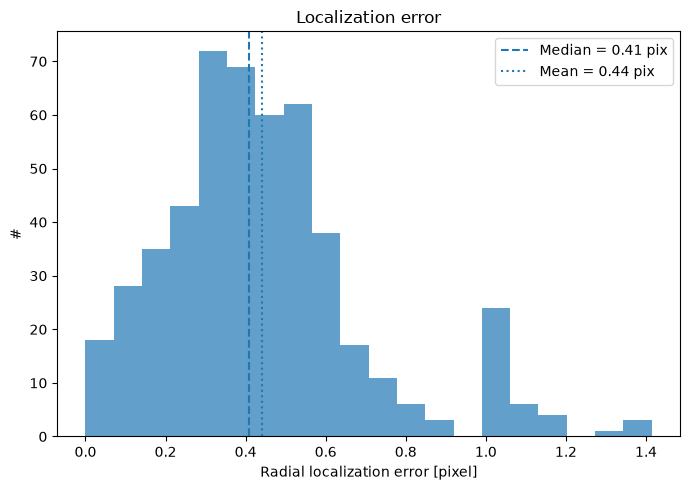

In [5]:
vals = matched["localization_error_pix"].to_numpy(float)
vals = vals[np.isfinite(vals)]

plt.figure(figsize=(7, 5))
plt.hist(vals, bins=20, alpha=0.7)
plt.axvline(
    np.median(vals),
    linestyle="--",
    label=f"Median = {np.median(vals):.2f} pix",
)
plt.axvline(
    np.mean(vals),
    linestyle=":",
    label=f"Mean = {np.mean(vals):.2f} pix",
)
plt.xlabel("Radial localization error [pixel]")
plt.ylabel("#")
plt.title("Localization error")
plt.legend()
plt.tight_layout()
plt.show()


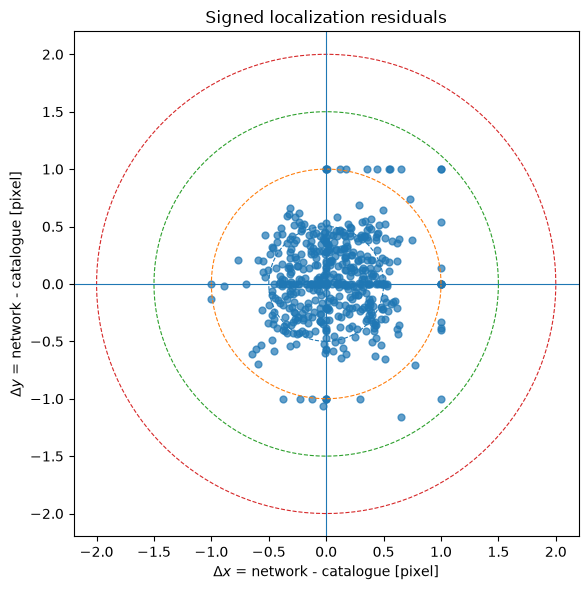

Mean signed offset: dx=0.065 pix, dy=0.028 pix


In [6]:
dx = matched["localization_dx_pix"].to_numpy(float)
dy = matched["localization_dy_pix"].to_numpy(float)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(dx, dy, s=24, alpha=0.7)

theta = np.linspace(0, 2*np.pi, 300)
for radius in [0.5, 1.0, 1.5, 2.0]:
    ax.plot(
        radius*np.cos(theta),
        radius*np.sin(theta),
        linestyle="--",
        linewidth=0.8,
    )

ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(r"$\Delta x$ = network - catalogue [pixel]")
ax.set_ylabel(r"$\Delta y$ = network - catalogue [pixel]")
ax.set_title("Signed localization residuals")
plt.tight_layout()
plt.show()

print(
    "Mean signed offset:",
    f"dx={np.nanmean(dx):.3f} pix,",
    f"dy={np.nanmean(dy):.3f} pix",
)


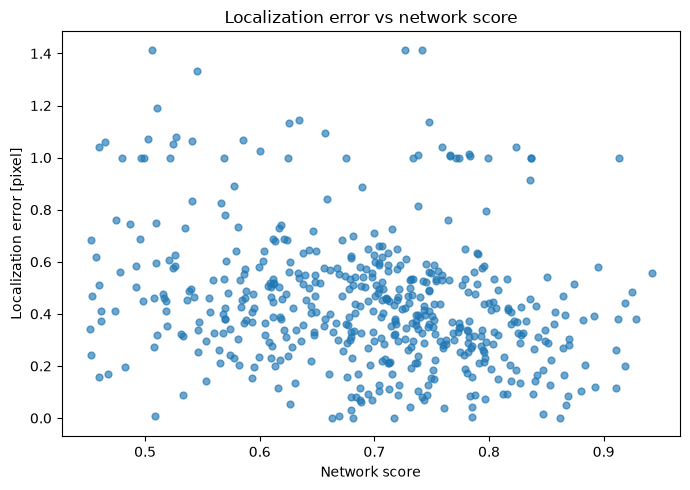

In [7]:
plot_df = matched[
    np.isfinite(matched["network_score"])
    & np.isfinite(matched["localization_error_pix"])
].copy()

plt.figure(figsize=(7, 5))
plt.scatter(
    plot_df["network_score"],
    plot_df["localization_error_pix"],
    s=24,
    alpha=0.65,
)
plt.xlabel("Network score")
plt.ylabel("Localization error [pixel]")
plt.title("Localization error vs network score")
plt.tight_layout()
plt.show()


## 4. Network score versus the real and synthetic PN domain

This section tests the training-domain-mismatch hypothesis directly.

For real catalogue PNe it shows:

1. `network_score` versus measured Hα/[O III], colored by recovered/missed status;
2. `network_score` versus catalogue \(m_{5007}\), colored by recovered/missed status;
3. the Hα/[O III]–\(m_{5007}\) plane, with real recovered/missed catalogue PNe overlaid on the synthetic PN distribution.

The synthetic points come from each injected PN's saved `metadata_json` (`line_fluxes` and `m5007`). They do **not** have a `network_score` in this notebook because the network is intentionally not rerun here. Their role is to show whether missed real PNe occupy regions poorly represented by the synthetic training population.

Only non-edge real catalogue PNe with finite, positive Hα/[O III] measurements are used.


Real catalogue PNe in domain plot : 526
Synthetic PN sources              : 15899
Synthetic central 98% ranges:
  Halpha/[O III] = 0.206 to 1.76
  m5007          = 22.10 to 27.87


,population,N,median_network_score,median_ha_over_oiii,median_m5007,fraction_inside_synthetic_1_99_box
0,Missed catalogue PN,68,0.368159,0.912581,25.9765,0.691176
1,Recovered catalogue PN,458,0.703479,0.333150,25.2575,0.864629


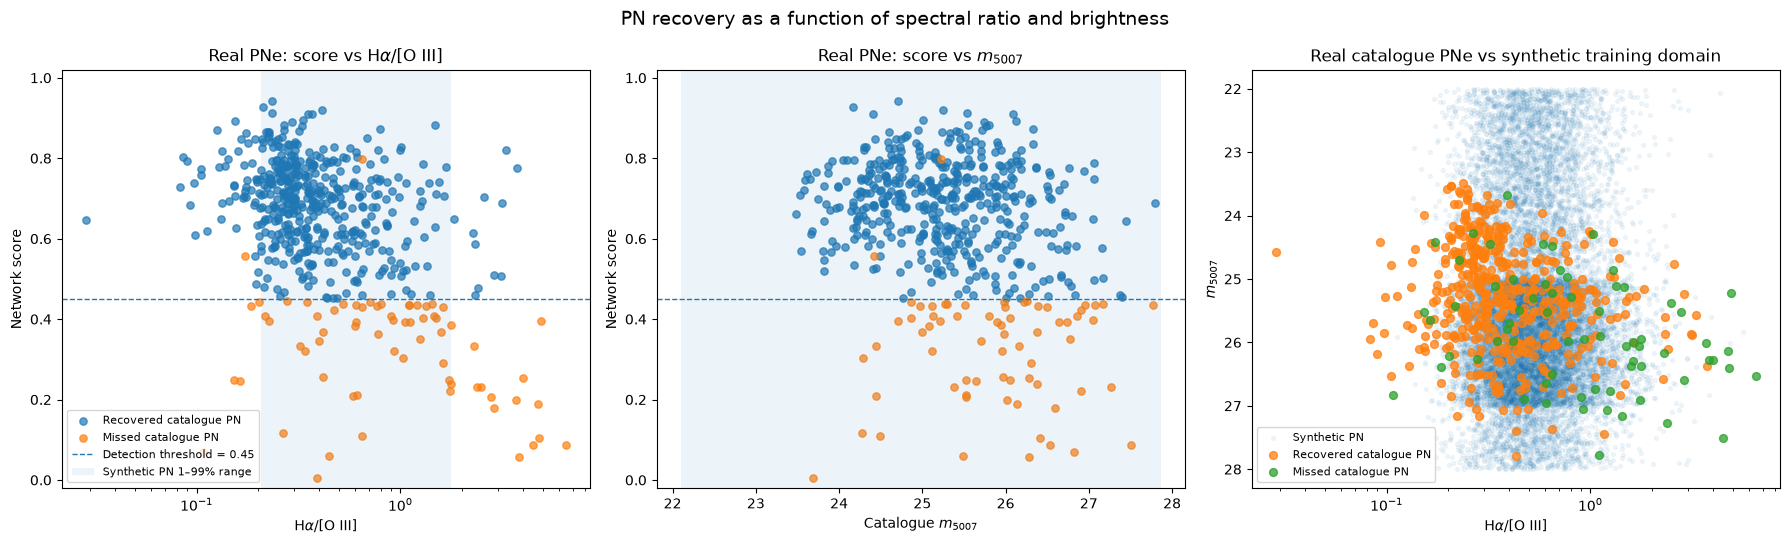

Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_post_inference_v1/network_score_vs_real_synthetic_domain.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_post_inference_v1/real_vs_synthetic_domain_coverage.csv


In [8]:
# ============================================================
# Real catalogue network score vs synthetic PN domain
# ============================================================

REAL_PN_POPULATIONS = [
    "Recovered catalogue PN",
    "Missed catalogue PN",
]

required_domain_columns = [
    "population",
    "network_score",
    "ha_over_oiii",
    "catalog_m5007",
    "edge_object",
]
missing = [c for c in required_domain_columns if c not in diagnostic_table.columns]
if missing:
    raise ValueError(
        "Cannot make the real-vs-synthetic domain plot. Missing columns: "
        + ", ".join(missing)
    )

# Use non-edge catalogue PNe with reliable measured Halpha/[O III].
real_pn_domain = diagnostic_table[
    diagnostic_table["population"].isin(REAL_PN_POPULATIONS)
    & (~diagnostic_table["edge_object"])
].copy()

real_pn_domain = real_pn_domain[
    np.isfinite(real_pn_domain["network_score"])
    & np.isfinite(real_pn_domain["ha_over_oiii"])
    & (real_pn_domain["ha_over_oiii"] > 0)
    & np.isfinite(real_pn_domain["catalog_m5007"])
].copy()

# The synthetic dataset already stores source-level physical metadata.
# We use metadata_json only, so this works whether X itself is stored raw
# or standardized and does not rerun the neural network.
with np.load(SYNTHETIC_DATASET, allow_pickle=True) as synth_npz:
    if "metadata_json" not in synth_npz:
        raise KeyError(f"{SYNTHETIC_DATASET} has no metadata_json field.")
    synthetic_metadata = json.loads(synth_npz["metadata_json"].item())

synthetic_rows = []
for sample_metadata in synthetic_metadata:
    for source in sample_metadata.get("sources", []):
        if str(source.get("class", "")).upper() != "PN":
            continue

        line_fluxes = source.get("line_fluxes", {})
        ha = float(line_fluxes.get("Halpha", np.nan))
        oiii = float(line_fluxes.get("OIII5007", np.nan))
        m5007 = float(source.get("m5007", np.nan))

        if (
            np.isfinite(ha)
            and np.isfinite(oiii)
            and oiii > 0
            and np.isfinite(m5007)
        ):
            synthetic_rows.append(
                {
                    "ha_over_oiii": ha / oiii,
                    "m5007": m5007,
                }
            )

synthetic_pn_domain = pd.DataFrame(synthetic_rows)

if len(synthetic_pn_domain) == 0:
    raise ValueError("No PN source metadata could be extracted from the synthetic dataset.")

print(f"Real catalogue PNe in domain plot : {len(real_pn_domain)}")
print(f"Synthetic PN sources              : {len(synthetic_pn_domain)}")

# ------------------------------------------------------------
# Quantify whether real PNe occupy the central synthetic domain
# ------------------------------------------------------------
syn_ratio_lo, syn_ratio_hi = np.percentile(
    synthetic_pn_domain["ha_over_oiii"], [1, 99]
)
syn_mag_lo, syn_mag_hi = np.percentile(
    synthetic_pn_domain["m5007"], [1, 99]
)

real_pn_domain["inside_synthetic_1_99_box"] = (
    real_pn_domain["ha_over_oiii"].between(syn_ratio_lo, syn_ratio_hi)
    & real_pn_domain["catalog_m5007"].between(syn_mag_lo, syn_mag_hi)
)

domain_coverage = (
    real_pn_domain.groupby("population")
    .agg(
        N=("object_id", "size"),
        median_network_score=("network_score", "median"),
        median_ha_over_oiii=("ha_over_oiii", "median"),
        median_m5007=("catalog_m5007", "median"),
        fraction_inside_synthetic_1_99_box=("inside_synthetic_1_99_box", "mean"),
    )
    .reset_index()
)

print(
    "Synthetic central 98% ranges:\n"
    f"  Halpha/[O III] = {syn_ratio_lo:.3g} to {syn_ratio_hi:.3g}\n"
    f"  m5007          = {syn_mag_lo:.2f} to {syn_mag_hi:.2f}"
)
display(domain_coverage)

domain_coverage.to_csv(
    OUTPUT_DIR / "real_vs_synthetic_domain_coverage.csv",
    index=False,
)

# ------------------------------------------------------------
# Three-panel diagnostic
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1) Score vs Halpha/[O III]
for population in REAL_PN_POPULATIONS:
    g = real_pn_domain[real_pn_domain["population"] == population]
    axes[0].scatter(
        g["ha_over_oiii"],
        g["network_score"],
        s=28,
        alpha=0.70,
        label=population,
    )

axes[0].axhline(
    DETECTION_THRESHOLD,
    linestyle="--",
    linewidth=1.0,
    label=f"Detection threshold = {DETECTION_THRESHOLD:.2f}",
)
axes[0].axvspan(
    syn_ratio_lo,
    syn_ratio_hi,
    alpha=0.08,
    label="Synthetic PN 1–99% range",
)
axes[0].set_xscale("log")
axes[0].set_ylim(-0.02, 1.02)
axes[0].set_xlabel(r"H$\alpha$/[O III]")
axes[0].set_ylabel("Network score")
axes[0].set_title(r"Real PNe: score vs H$\alpha$/[O III]")
axes[0].legend(fontsize=8)

# 2) Score vs catalogue m5007
for population in REAL_PN_POPULATIONS:
    g = real_pn_domain[real_pn_domain["population"] == population]
    axes[1].scatter(
        g["catalog_m5007"],
        g["network_score"],
        s=28,
        alpha=0.70,
        label=population,
    )

axes[1].axhline(
    DETECTION_THRESHOLD,
    linestyle="--",
    linewidth=1.0,
)
axes[1].axvspan(
    syn_mag_lo,
    syn_mag_hi,
    alpha=0.08,
)
axes[1].set_ylim(-0.02, 1.02)
axes[1].set_xlabel(r"Catalogue $m_{5007}$")
axes[1].set_ylabel("Network score")
axes[1].set_title(r"Real PNe: score vs $m_{5007}$")

# 3) Real and synthetic distributions in the physical parameter plane.
axes[2].scatter(
    synthetic_pn_domain["ha_over_oiii"],
    synthetic_pn_domain["m5007"],
    s=8,
    alpha=0.06,
    rasterized=True,
    label="Synthetic PN",
)

for population in REAL_PN_POPULATIONS:
    g = real_pn_domain[real_pn_domain["population"] == population]
    axes[2].scatter(
        g["ha_over_oiii"],
        g["catalog_m5007"],
        s=32,
        alpha=0.75,
        label=population,
    )

axes[2].set_xscale("log")
axes[2].invert_yaxis()
axes[2].set_xlabel(r"H$\alpha$/[O III]")
axes[2].set_ylabel(r"$m_{5007}$")
axes[2].set_title("Real catalogue PNe vs synthetic training domain")
axes[2].legend(fontsize=8)

fig.suptitle(
    "PN recovery as a function of spectral ratio and brightness",
    fontsize=14,
)
plt.tight_layout()

domain_plot_path = OUTPUT_DIR / "network_score_vs_real_synthetic_domain.png"
#fig.savefig(domain_plot_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", domain_plot_path)
print("Saved:", OUTPUT_DIR / "real_vs_synthetic_domain_coverage.csv")


## 5. Select 20 matched, 20 missed, and 20 unmatched objects

Sampling is random but reproducible. Edge objects are excluded because they cannot support a complete centered 32×32 cutout.



Sample sizes:


,population,score_bin,N
0,Missed catalogue PN,0.15–0.30,10
1,Missed catalogue PN,0.30–0.45,10
2,Missed catalogue PN,<0.15,10
3,Recovered catalogue PN,0.45–0.60,10
4,Recovered catalogue PN,0.60–0.80,10
5,Recovered catalogue PN,>=0.80,10
6,Unmatched candidate,0.45–0.60,10
7,Unmatched candidate,0.60–0.80,10
8,Unmatched candidate,>=0.80,10


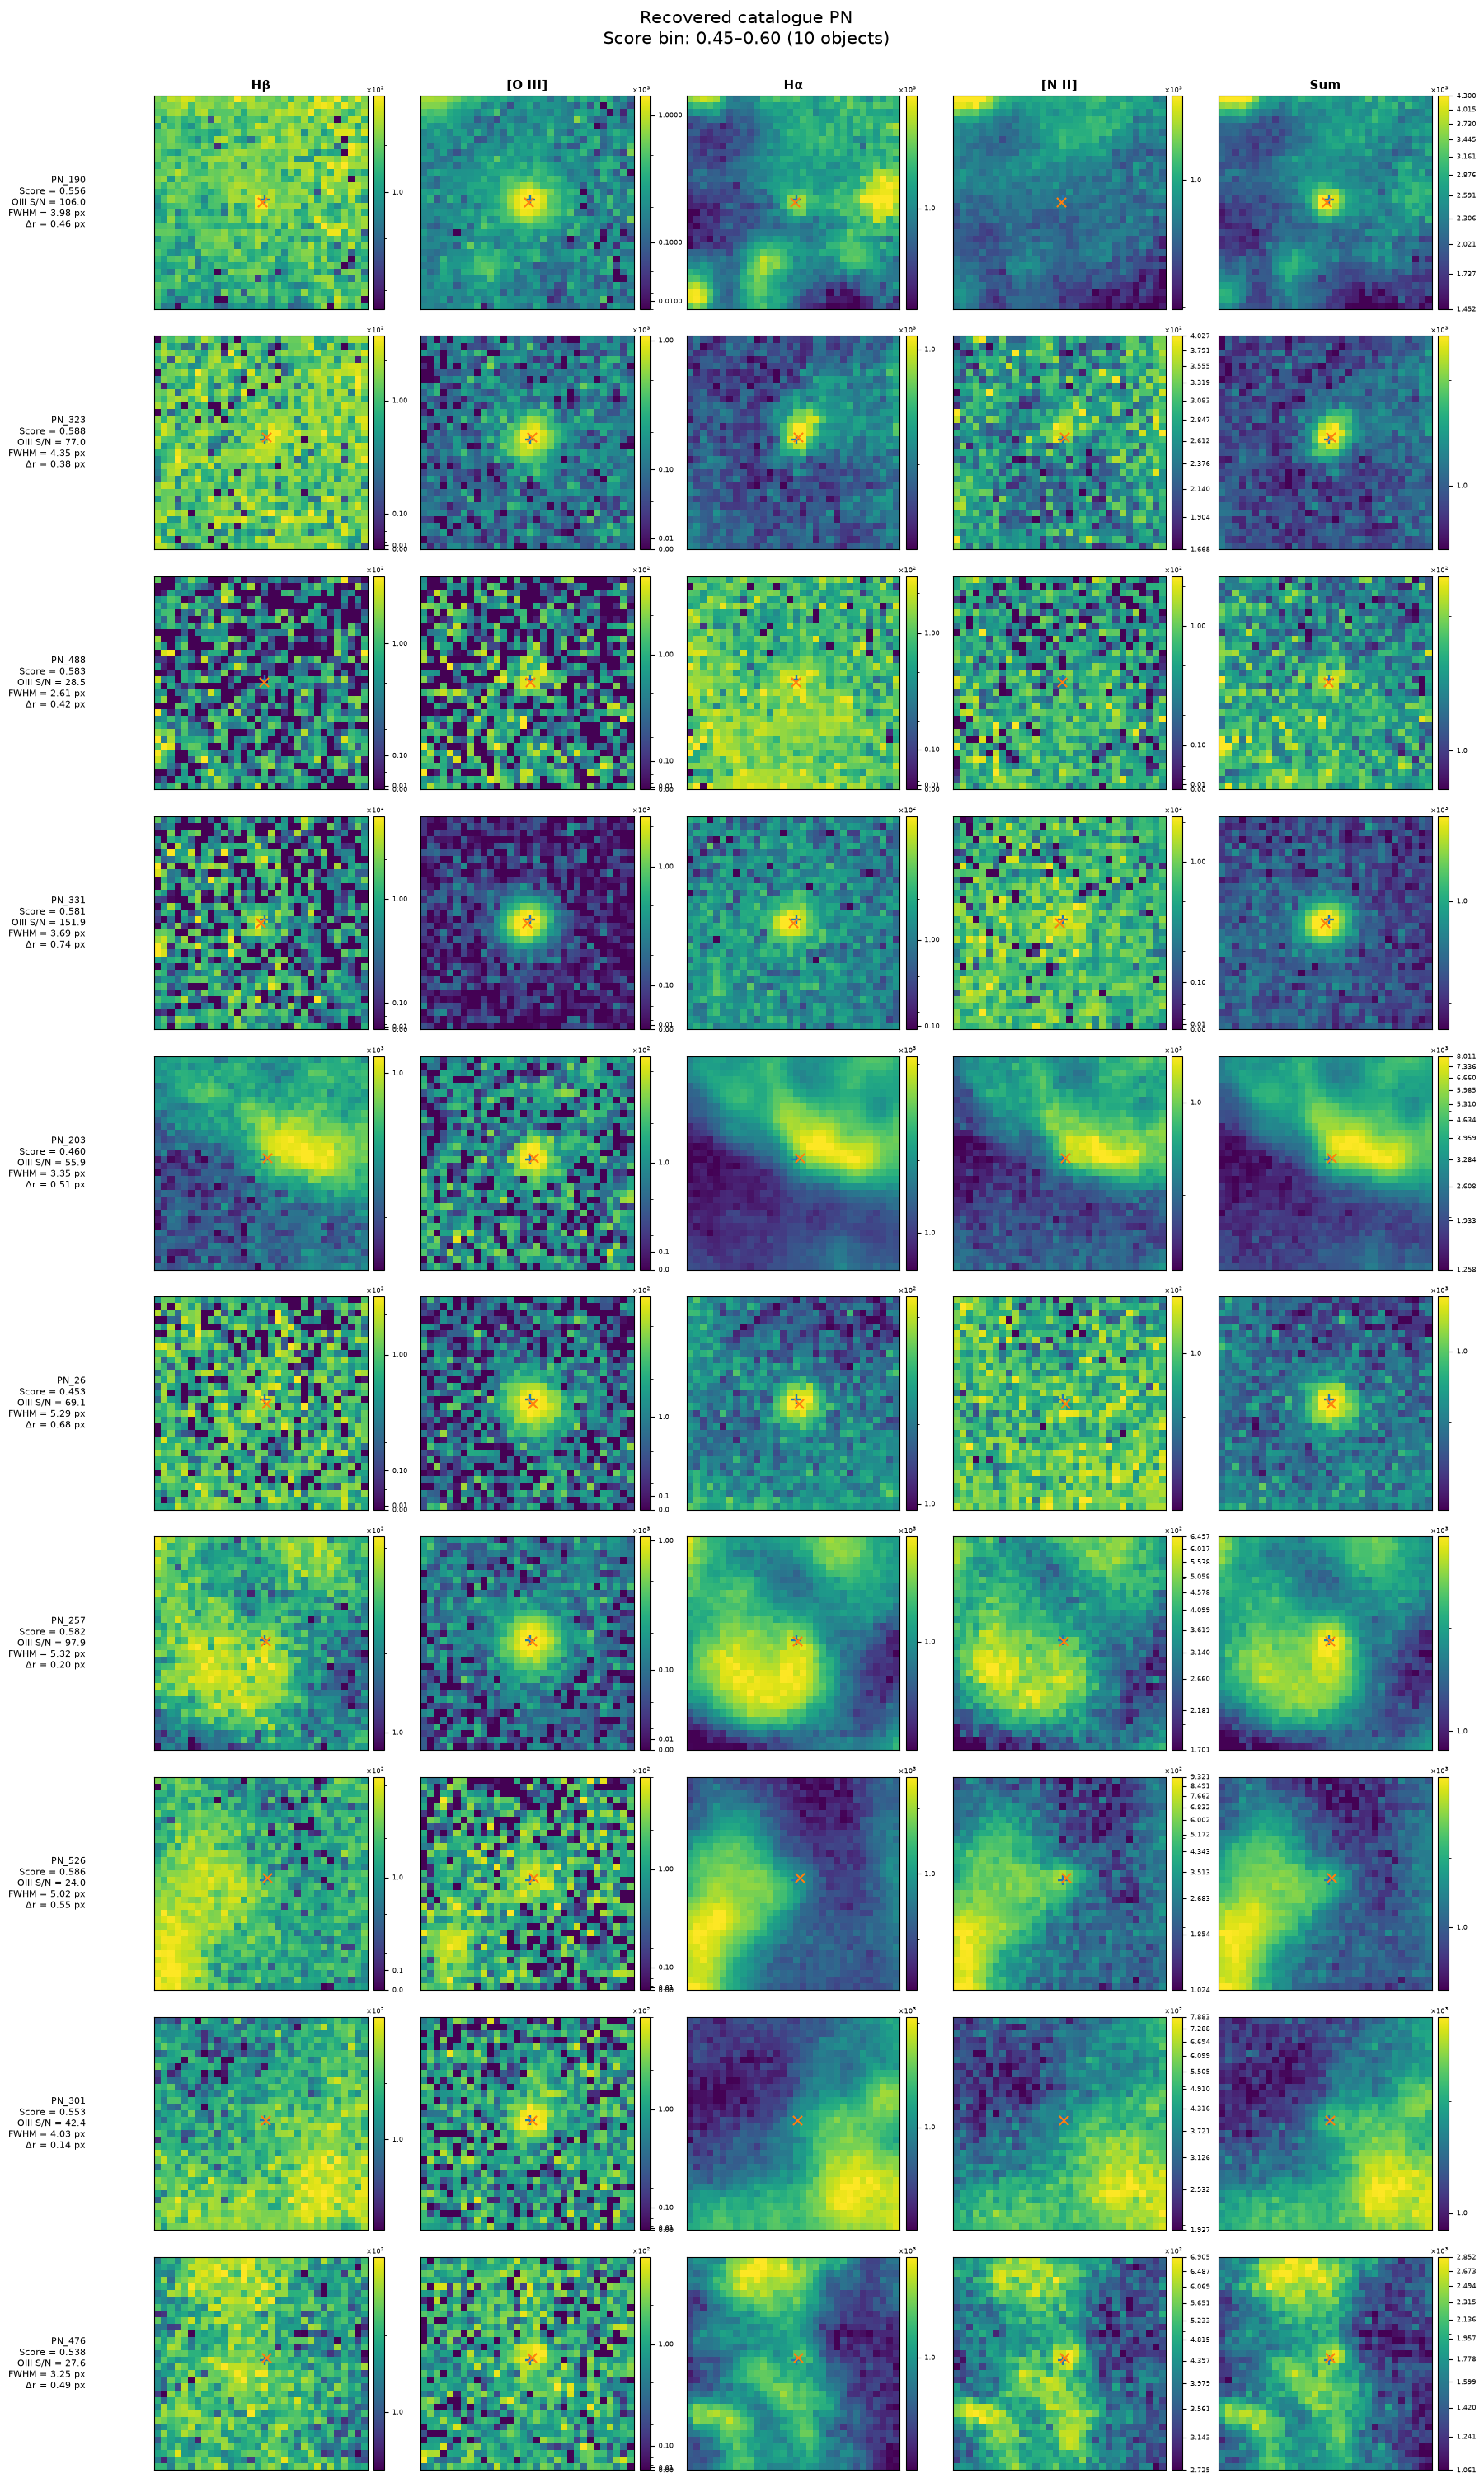

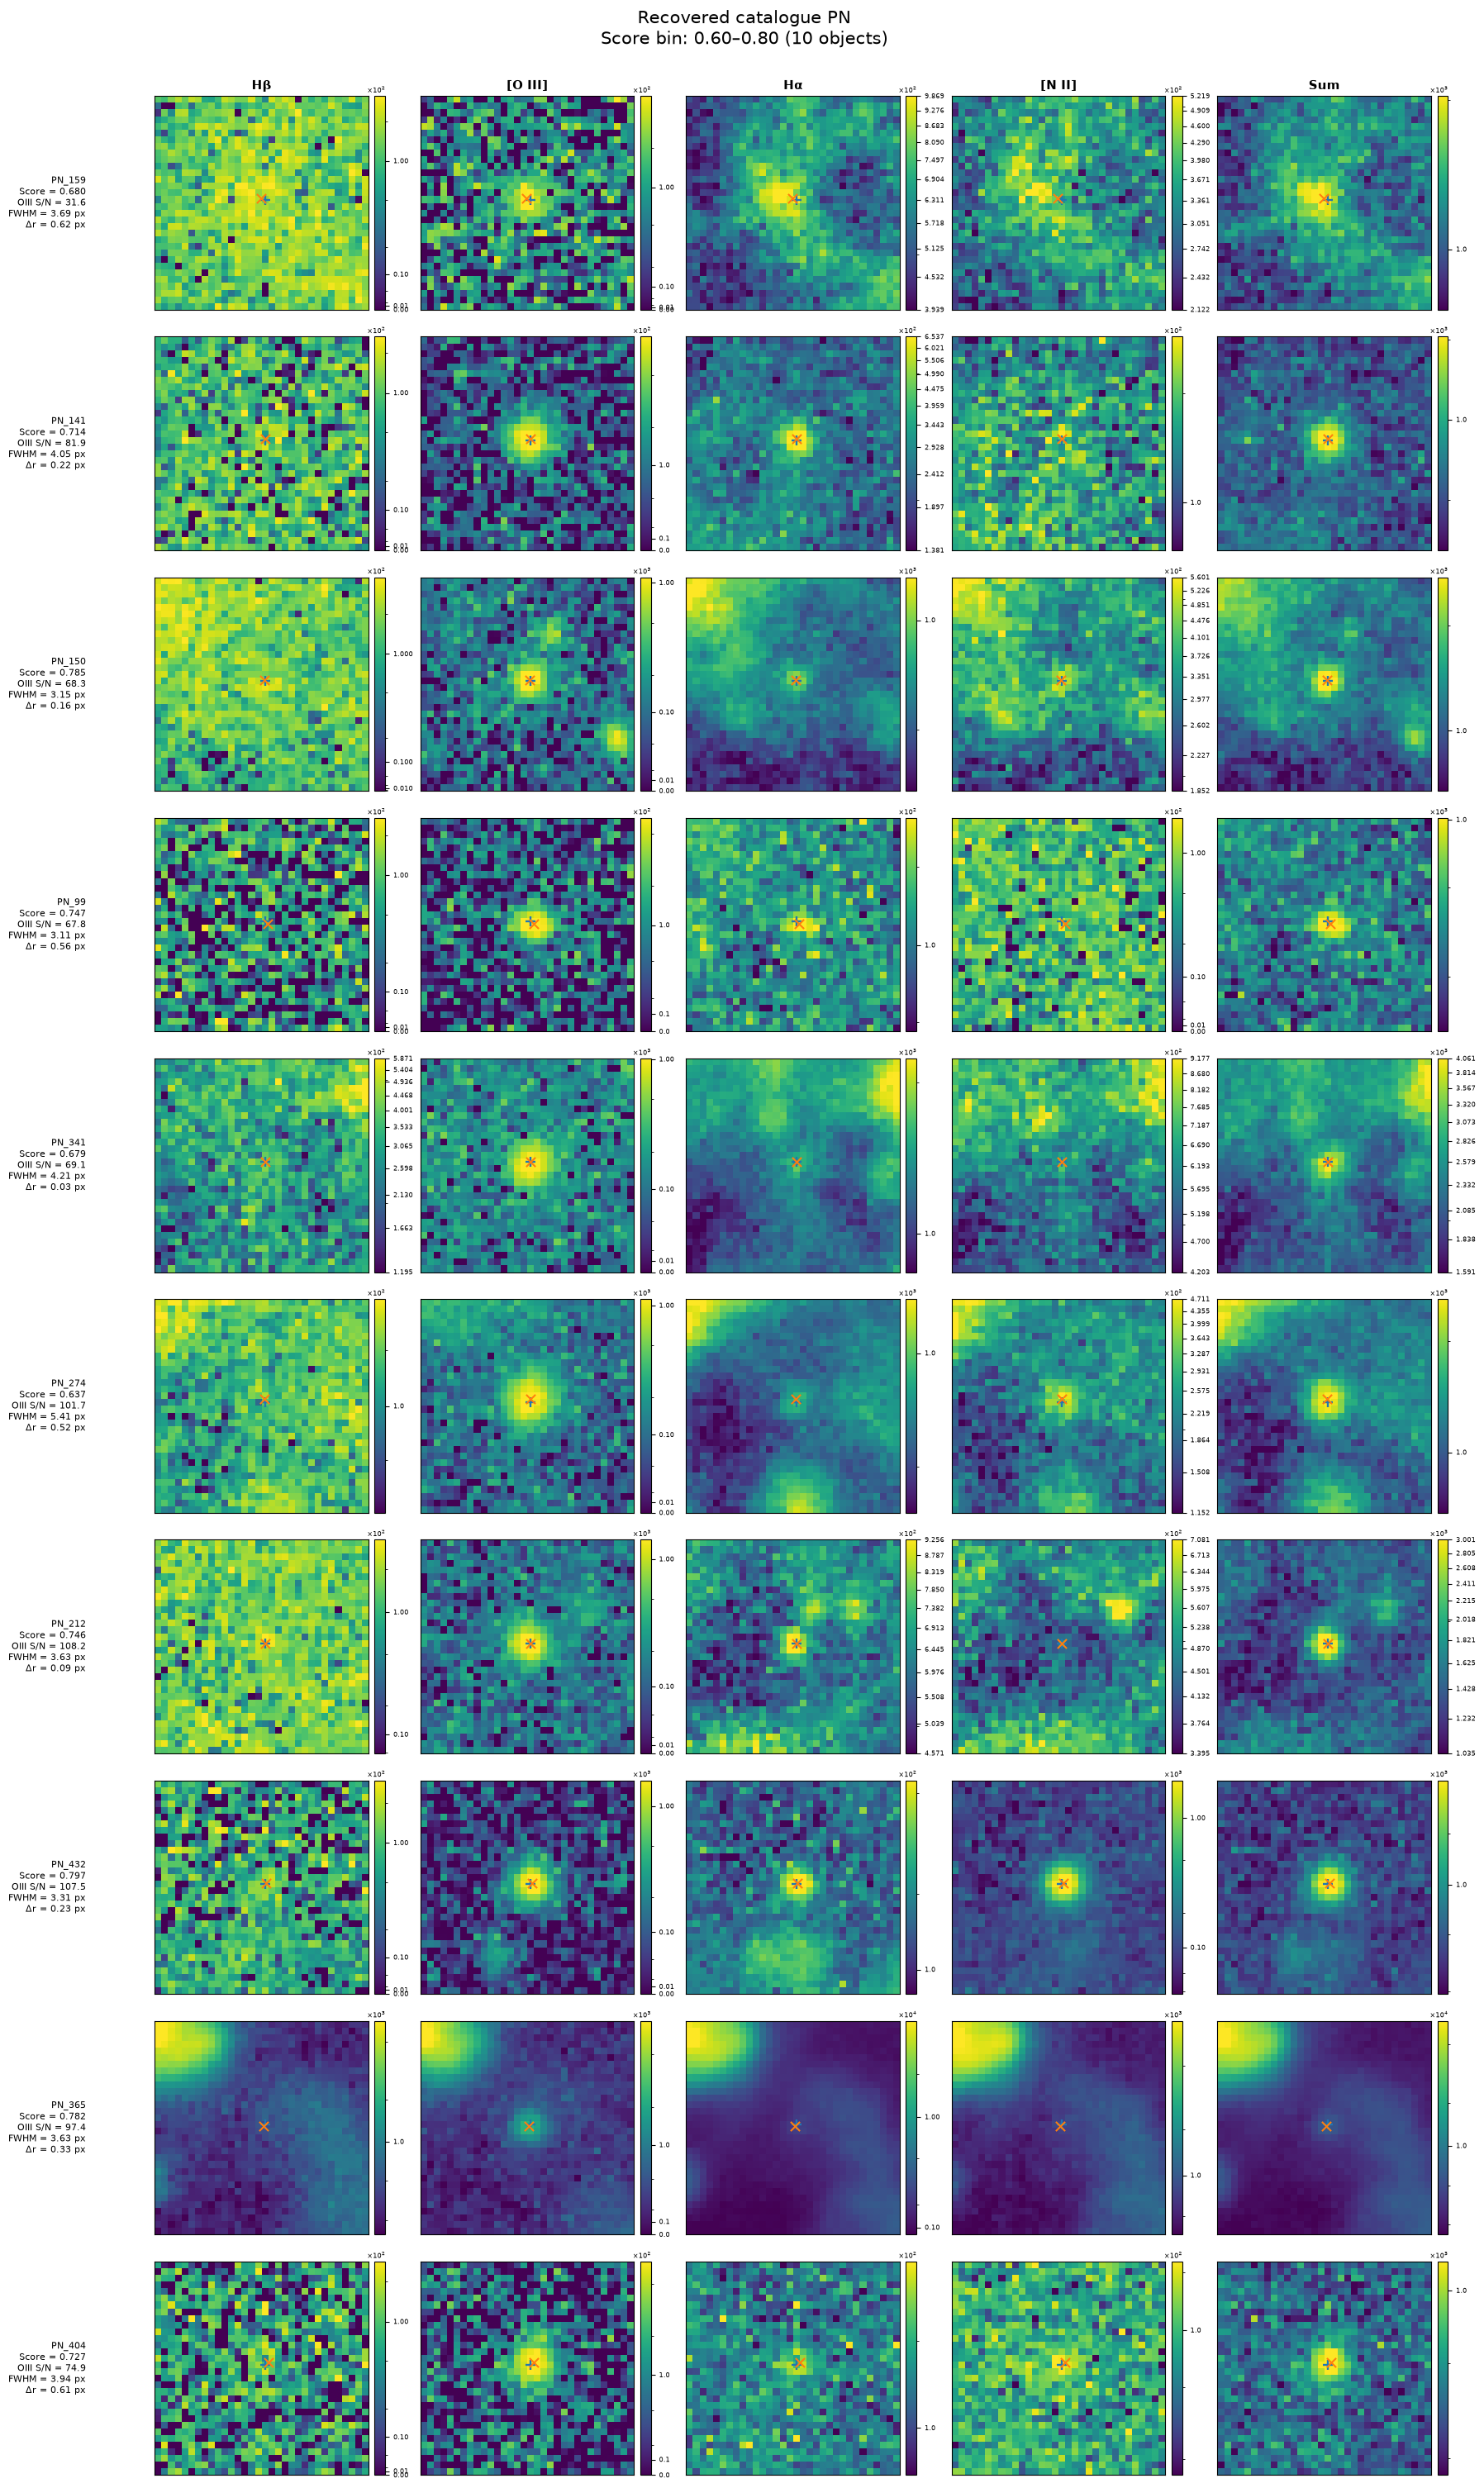

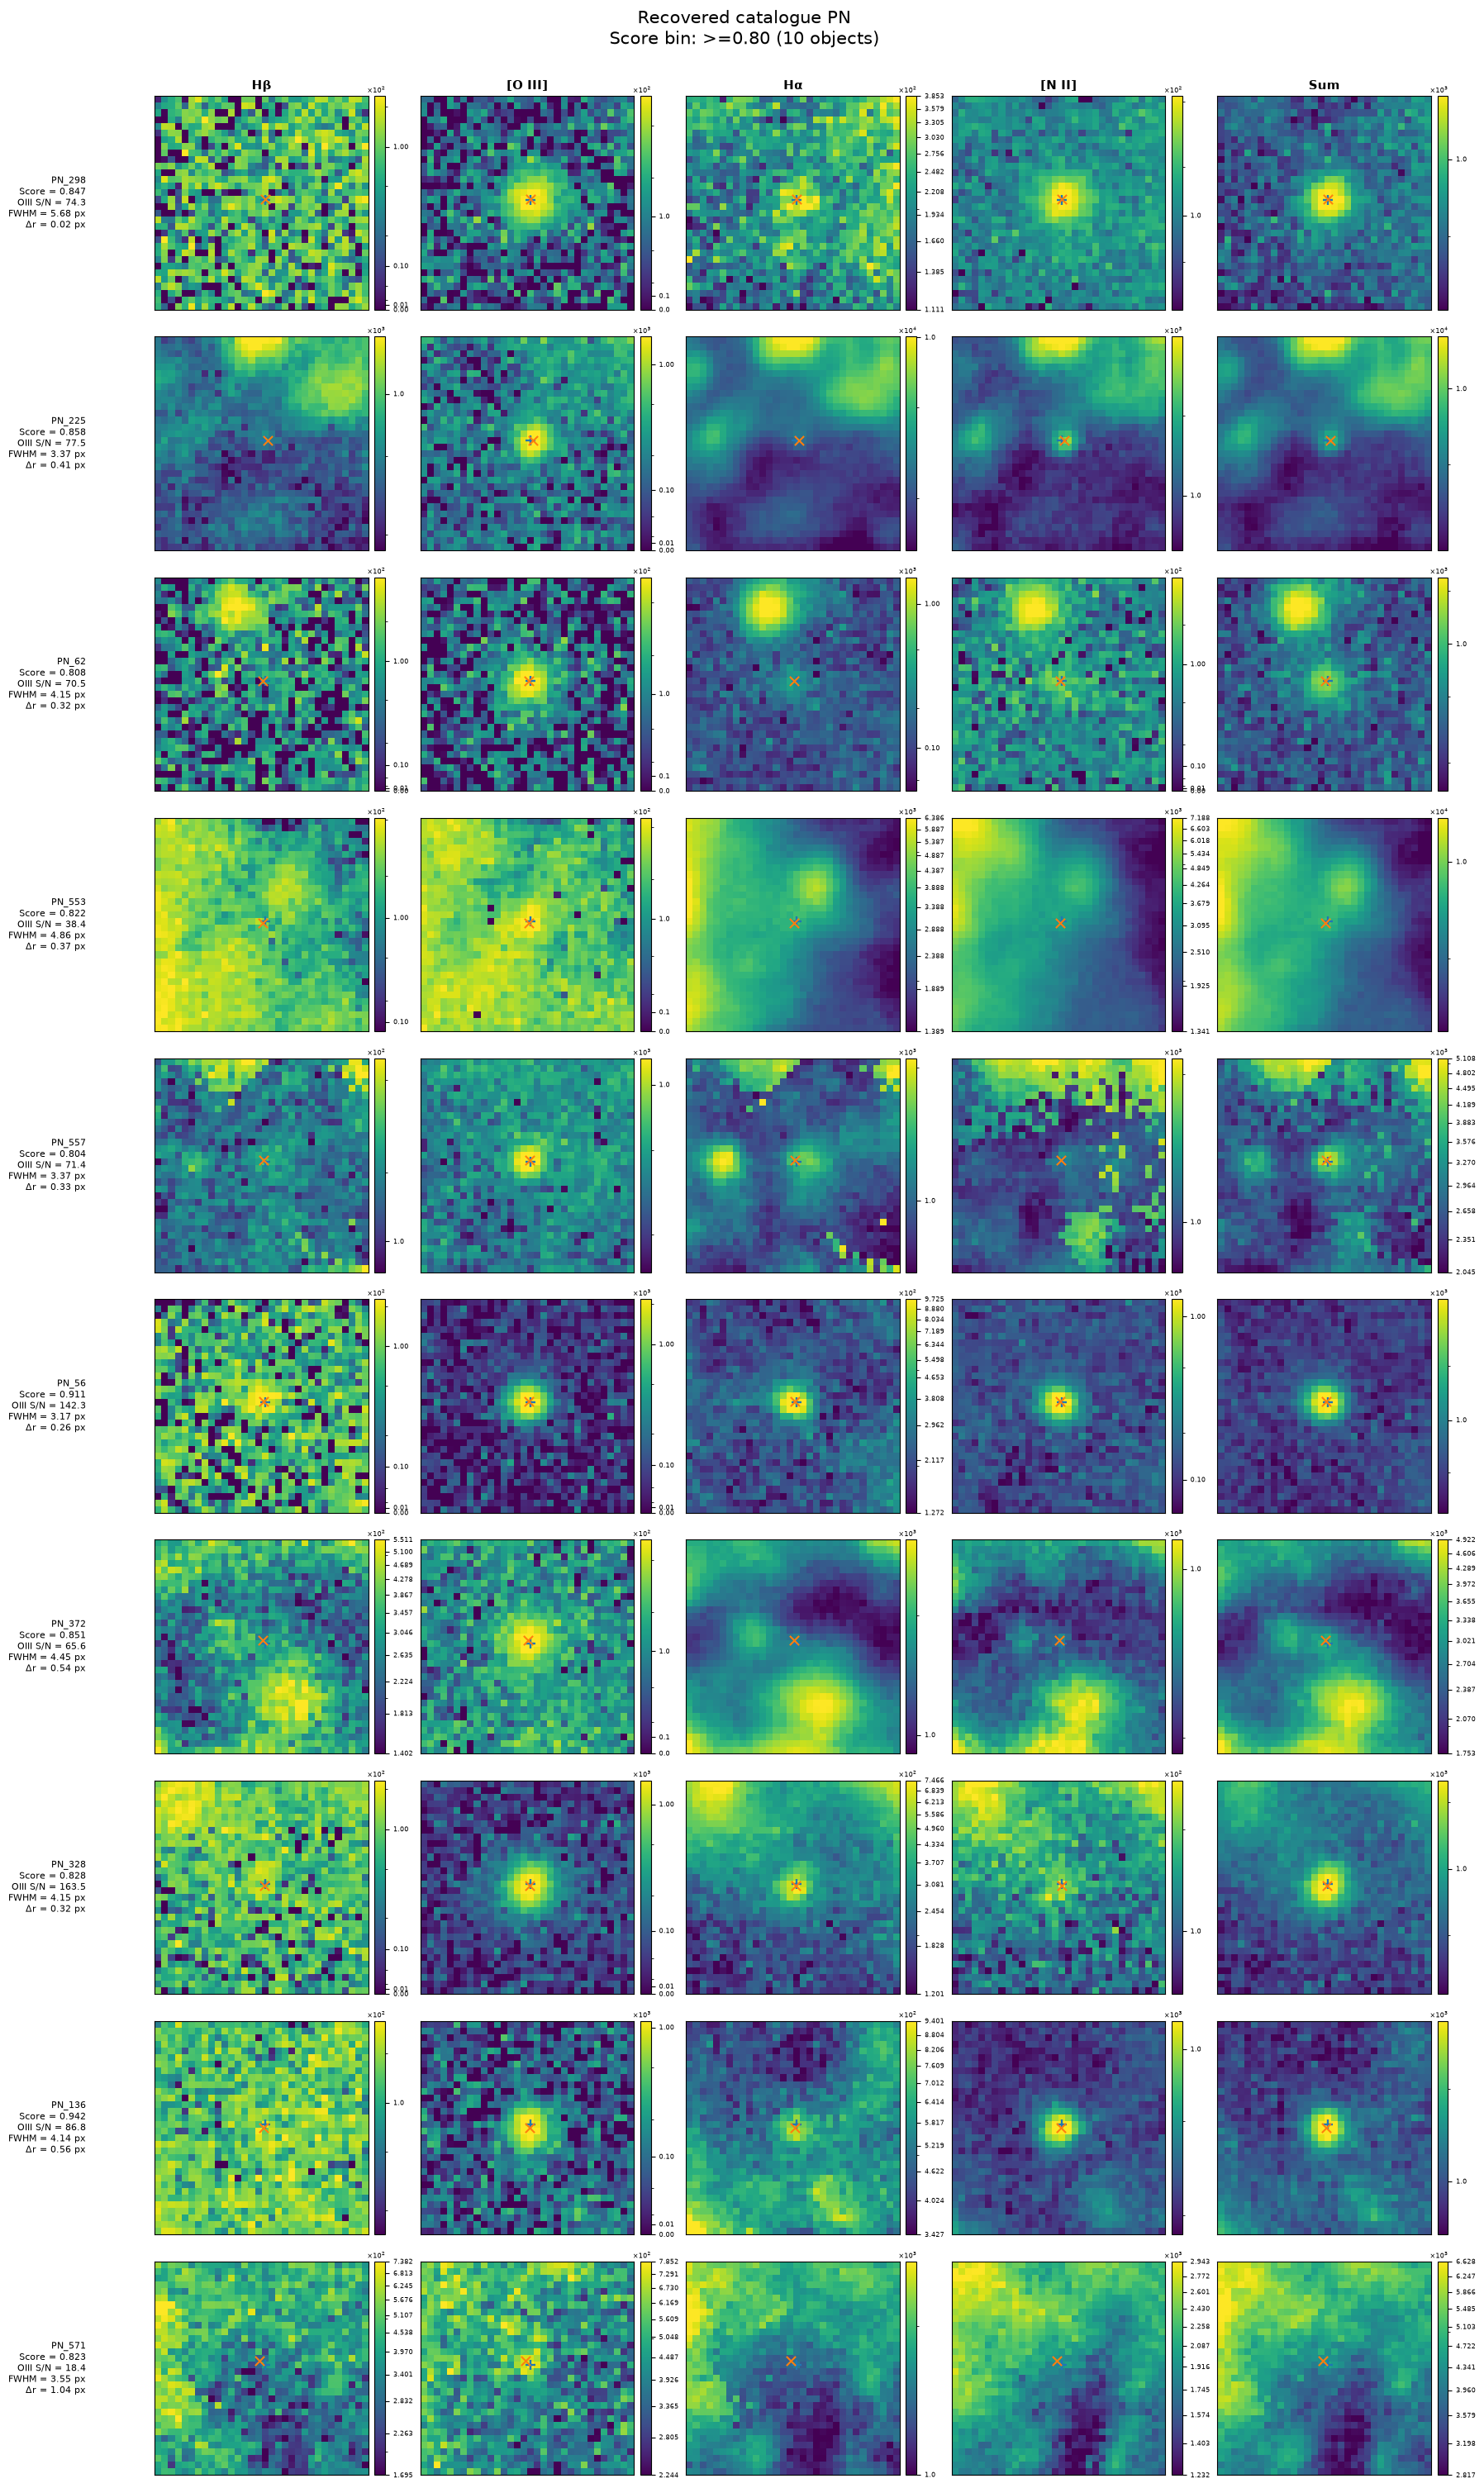

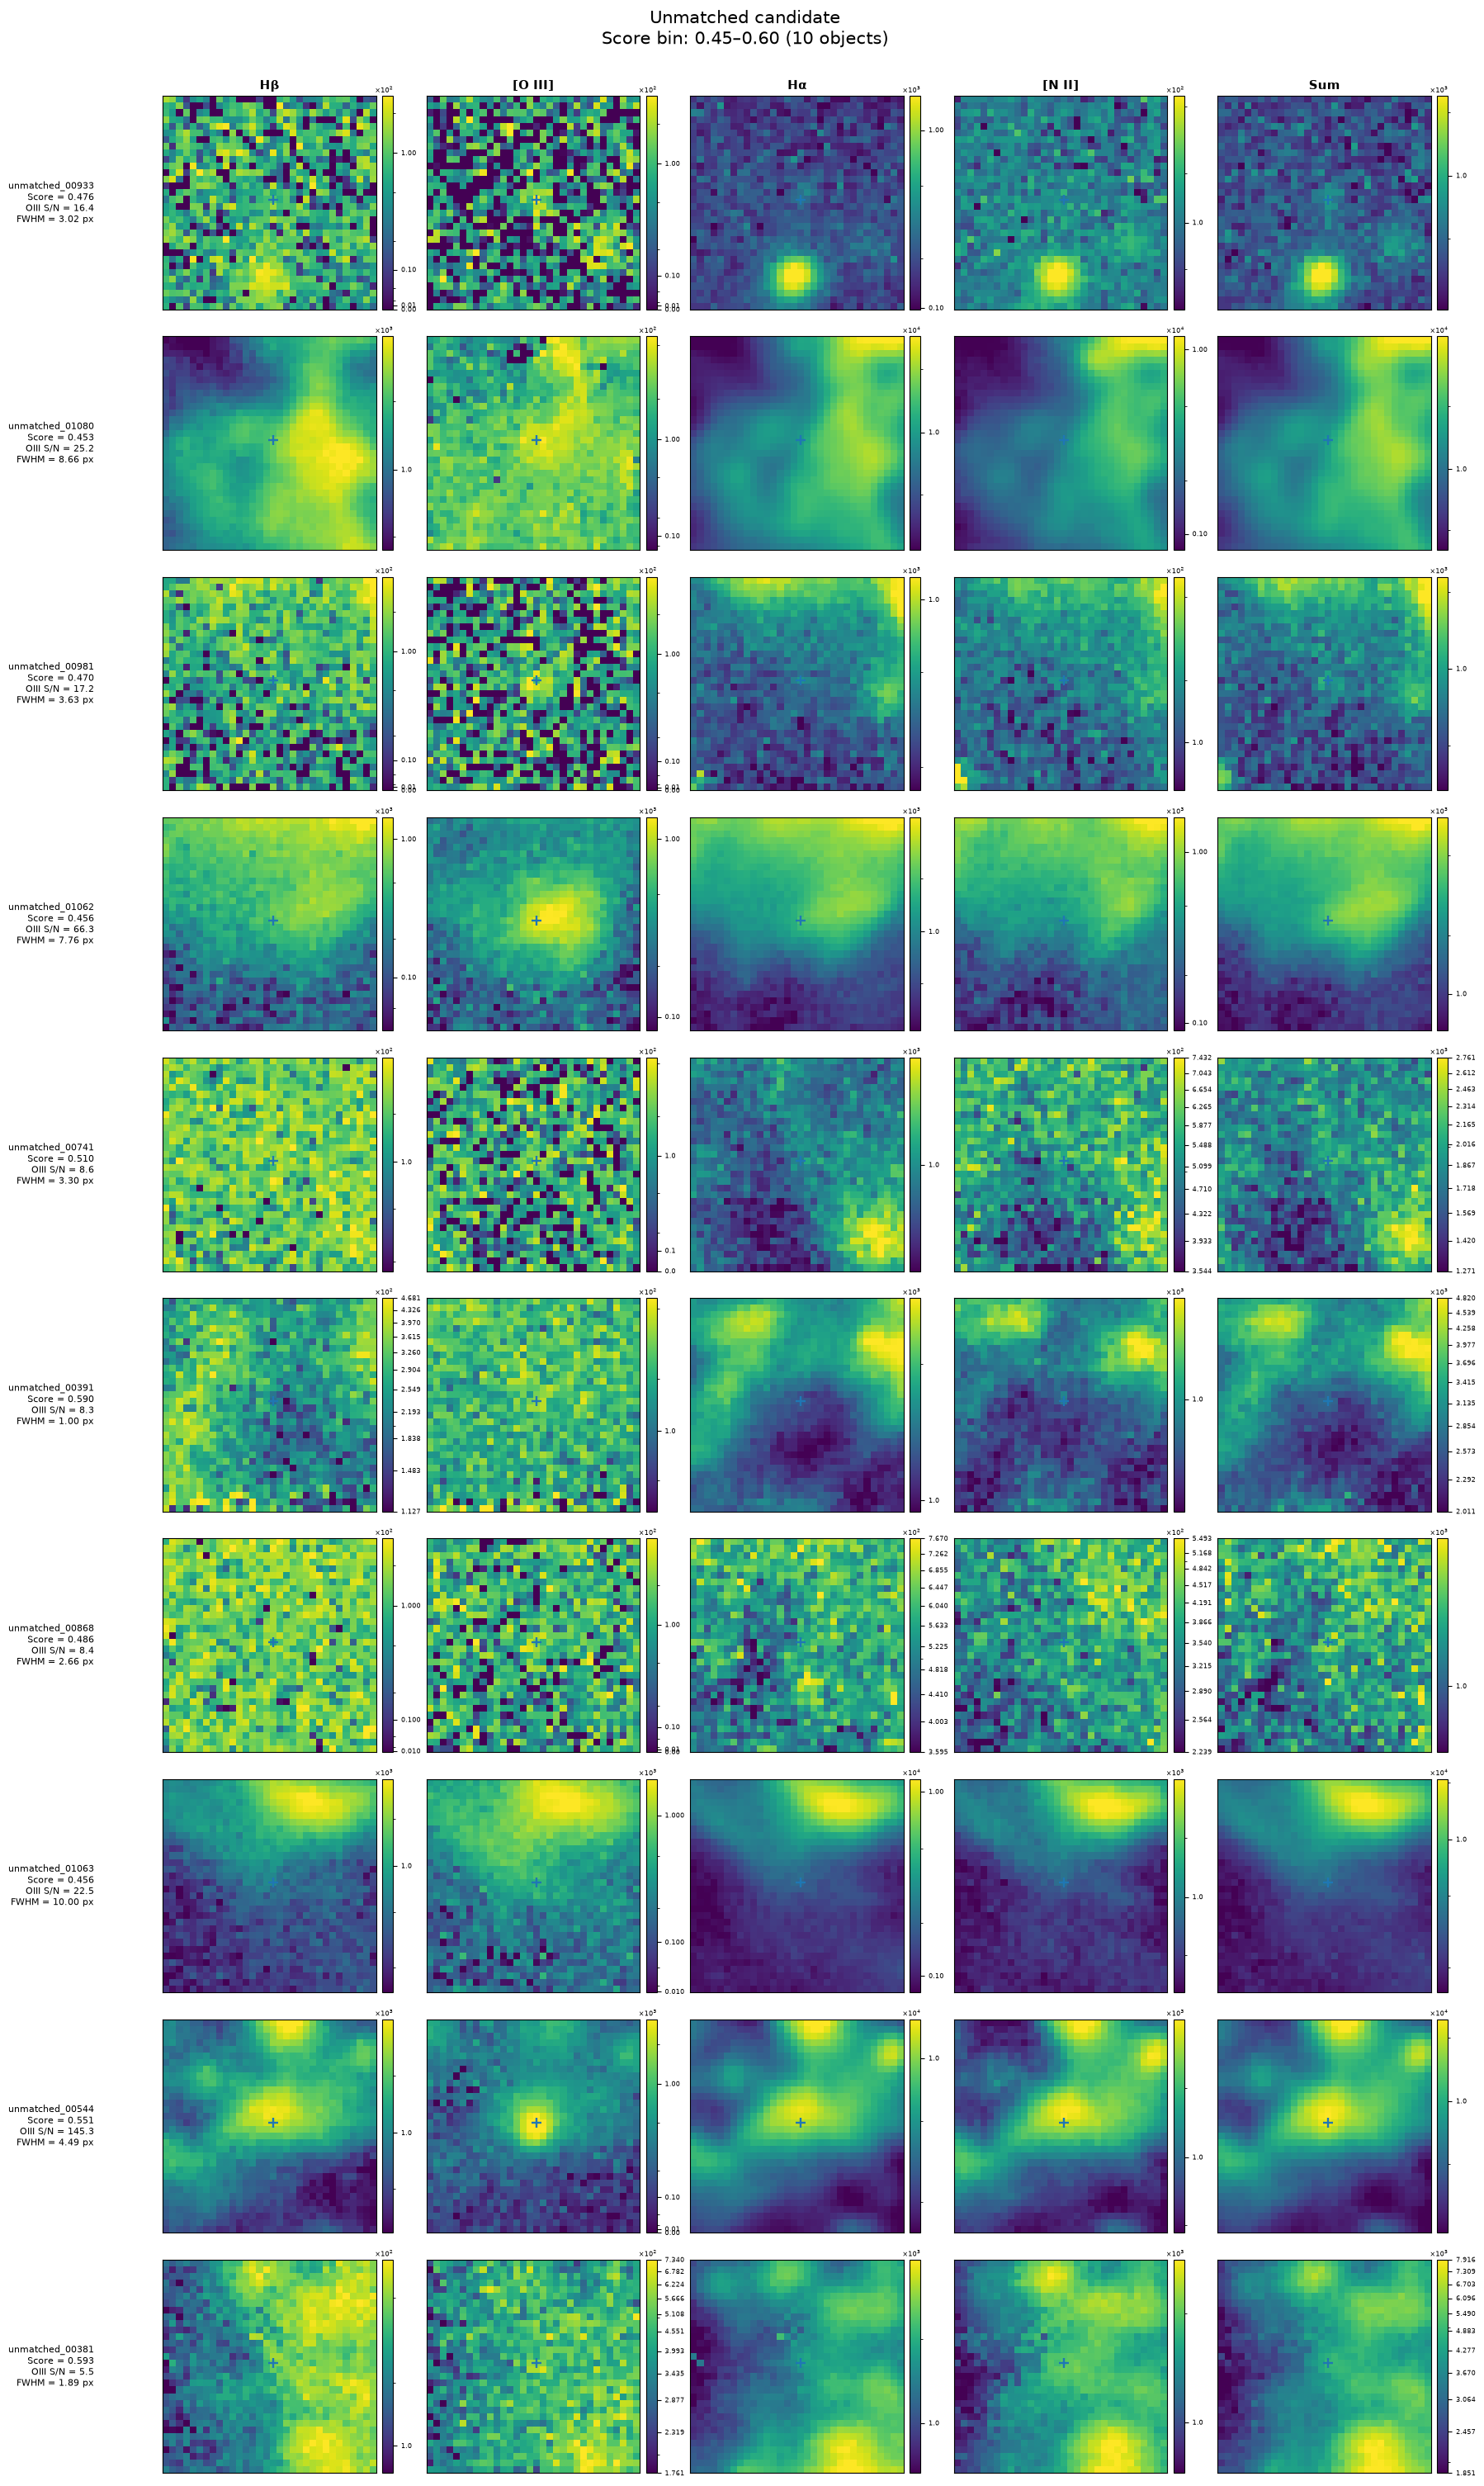

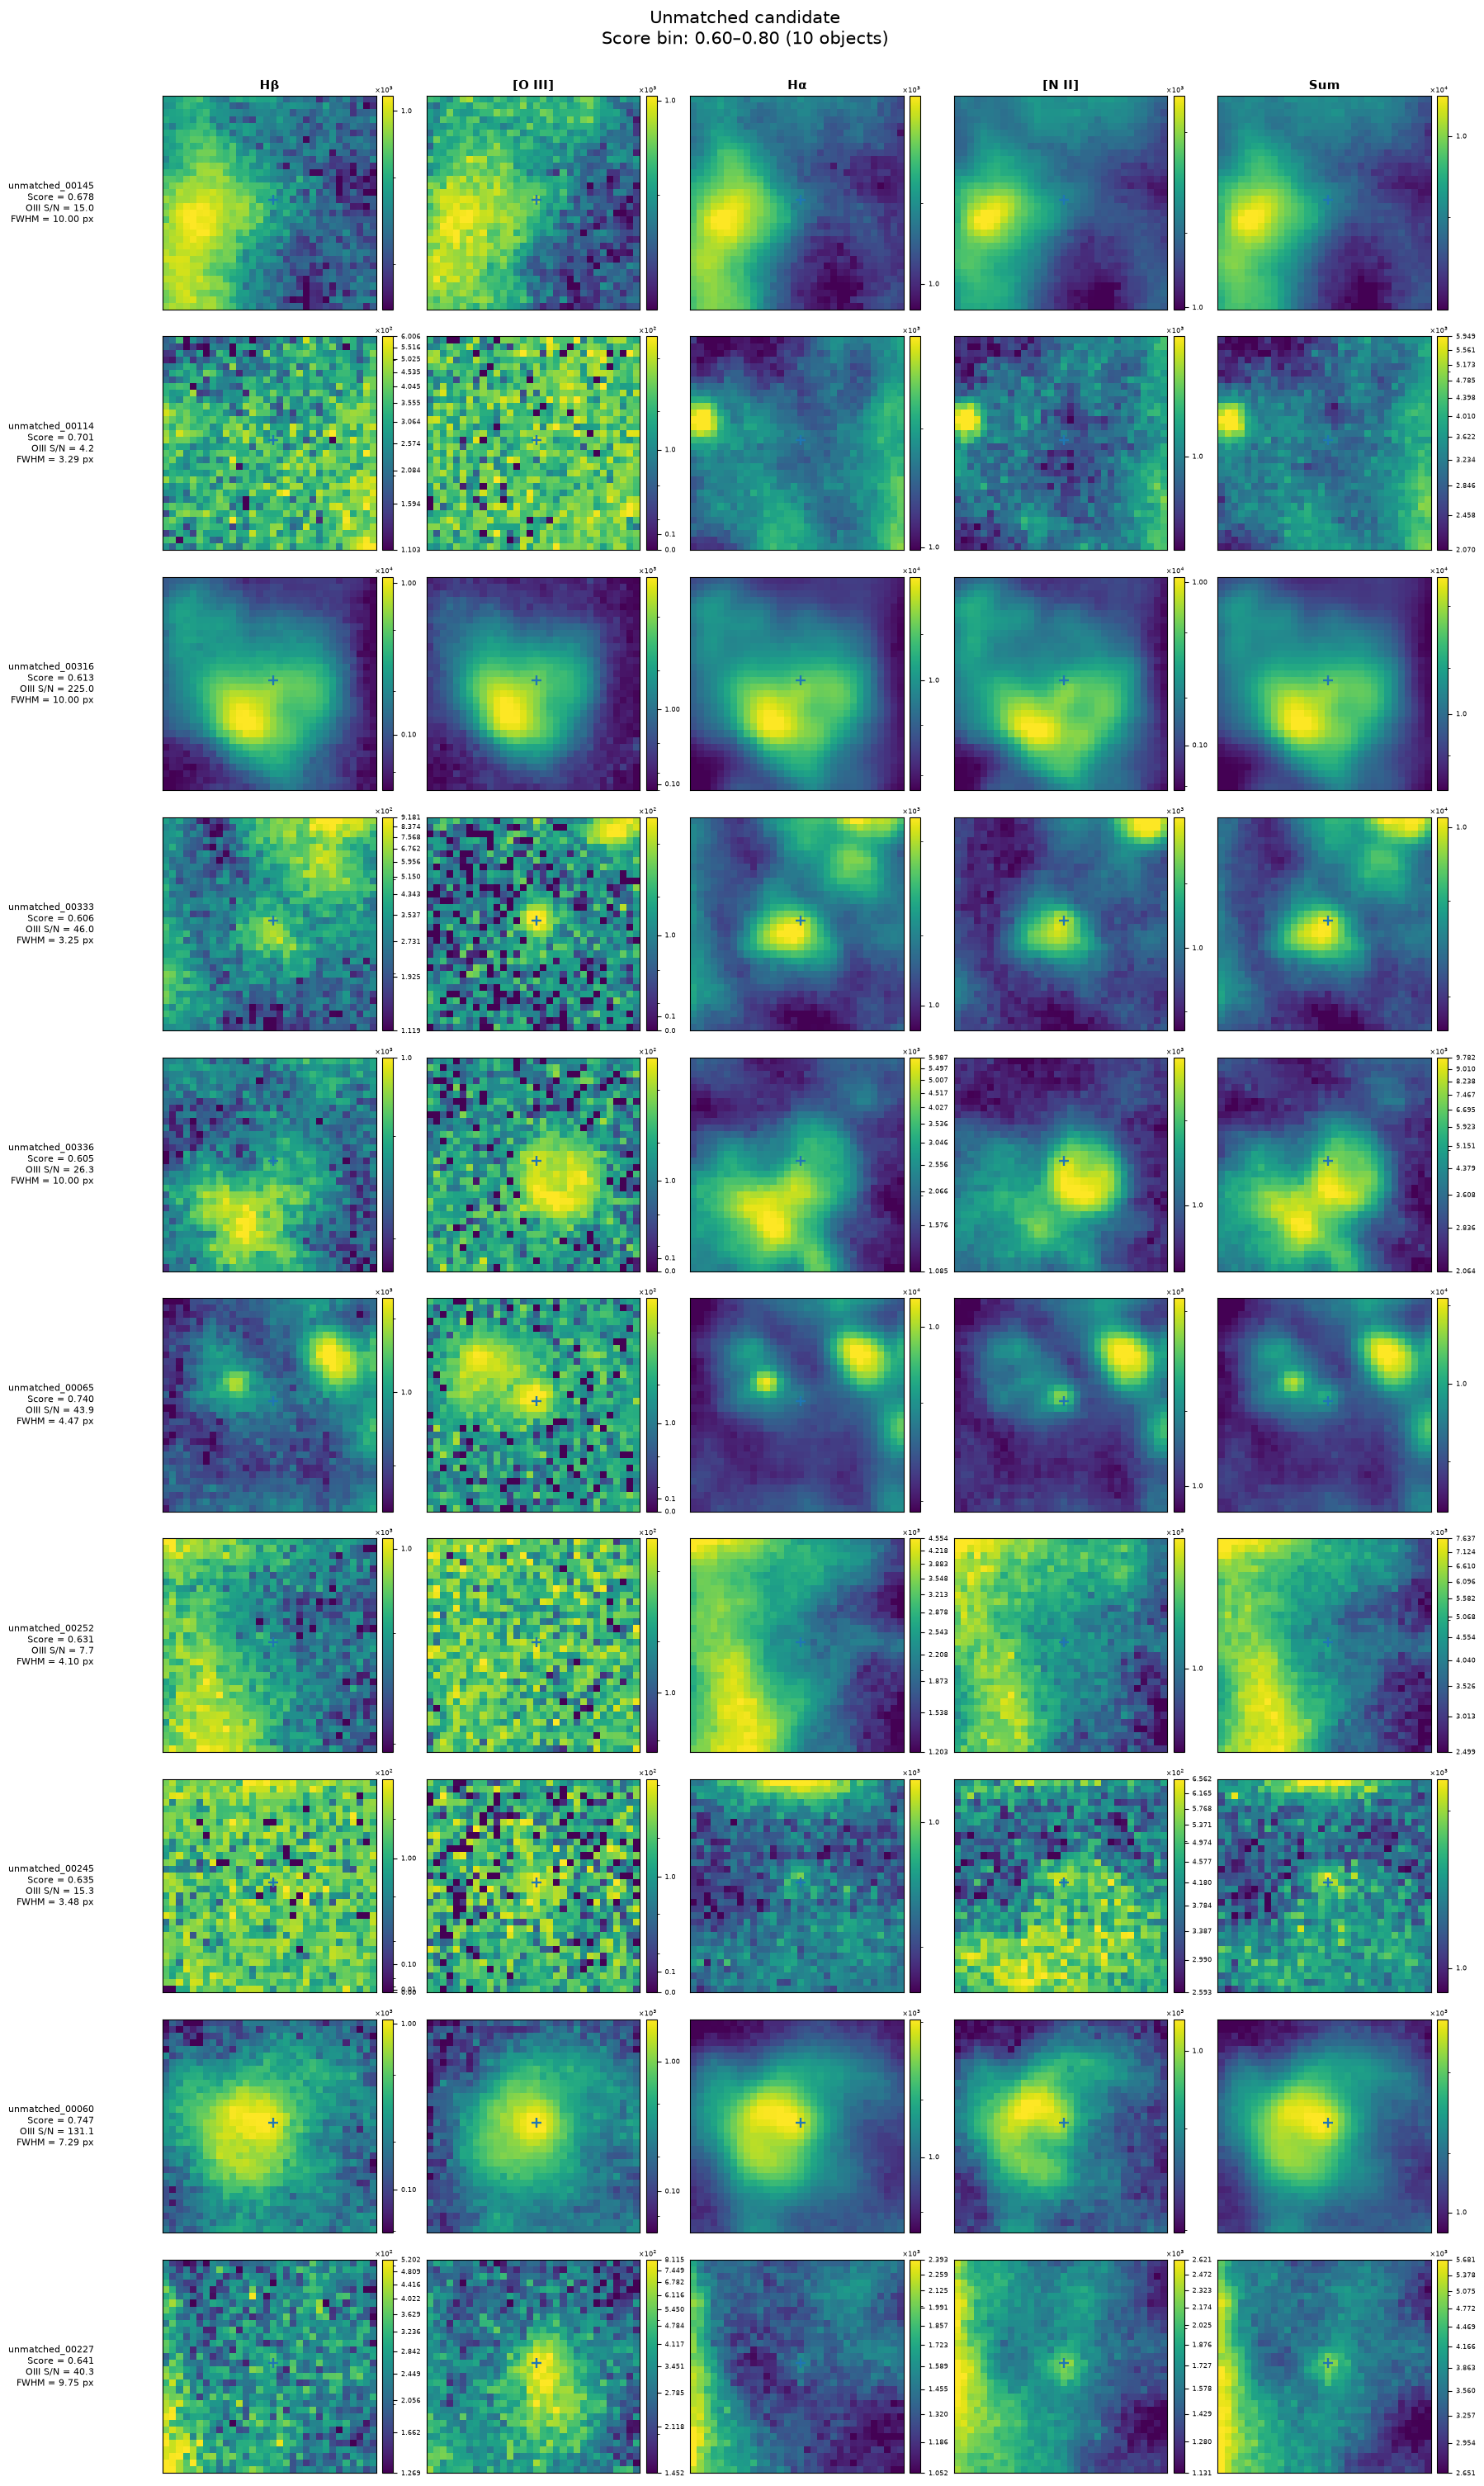

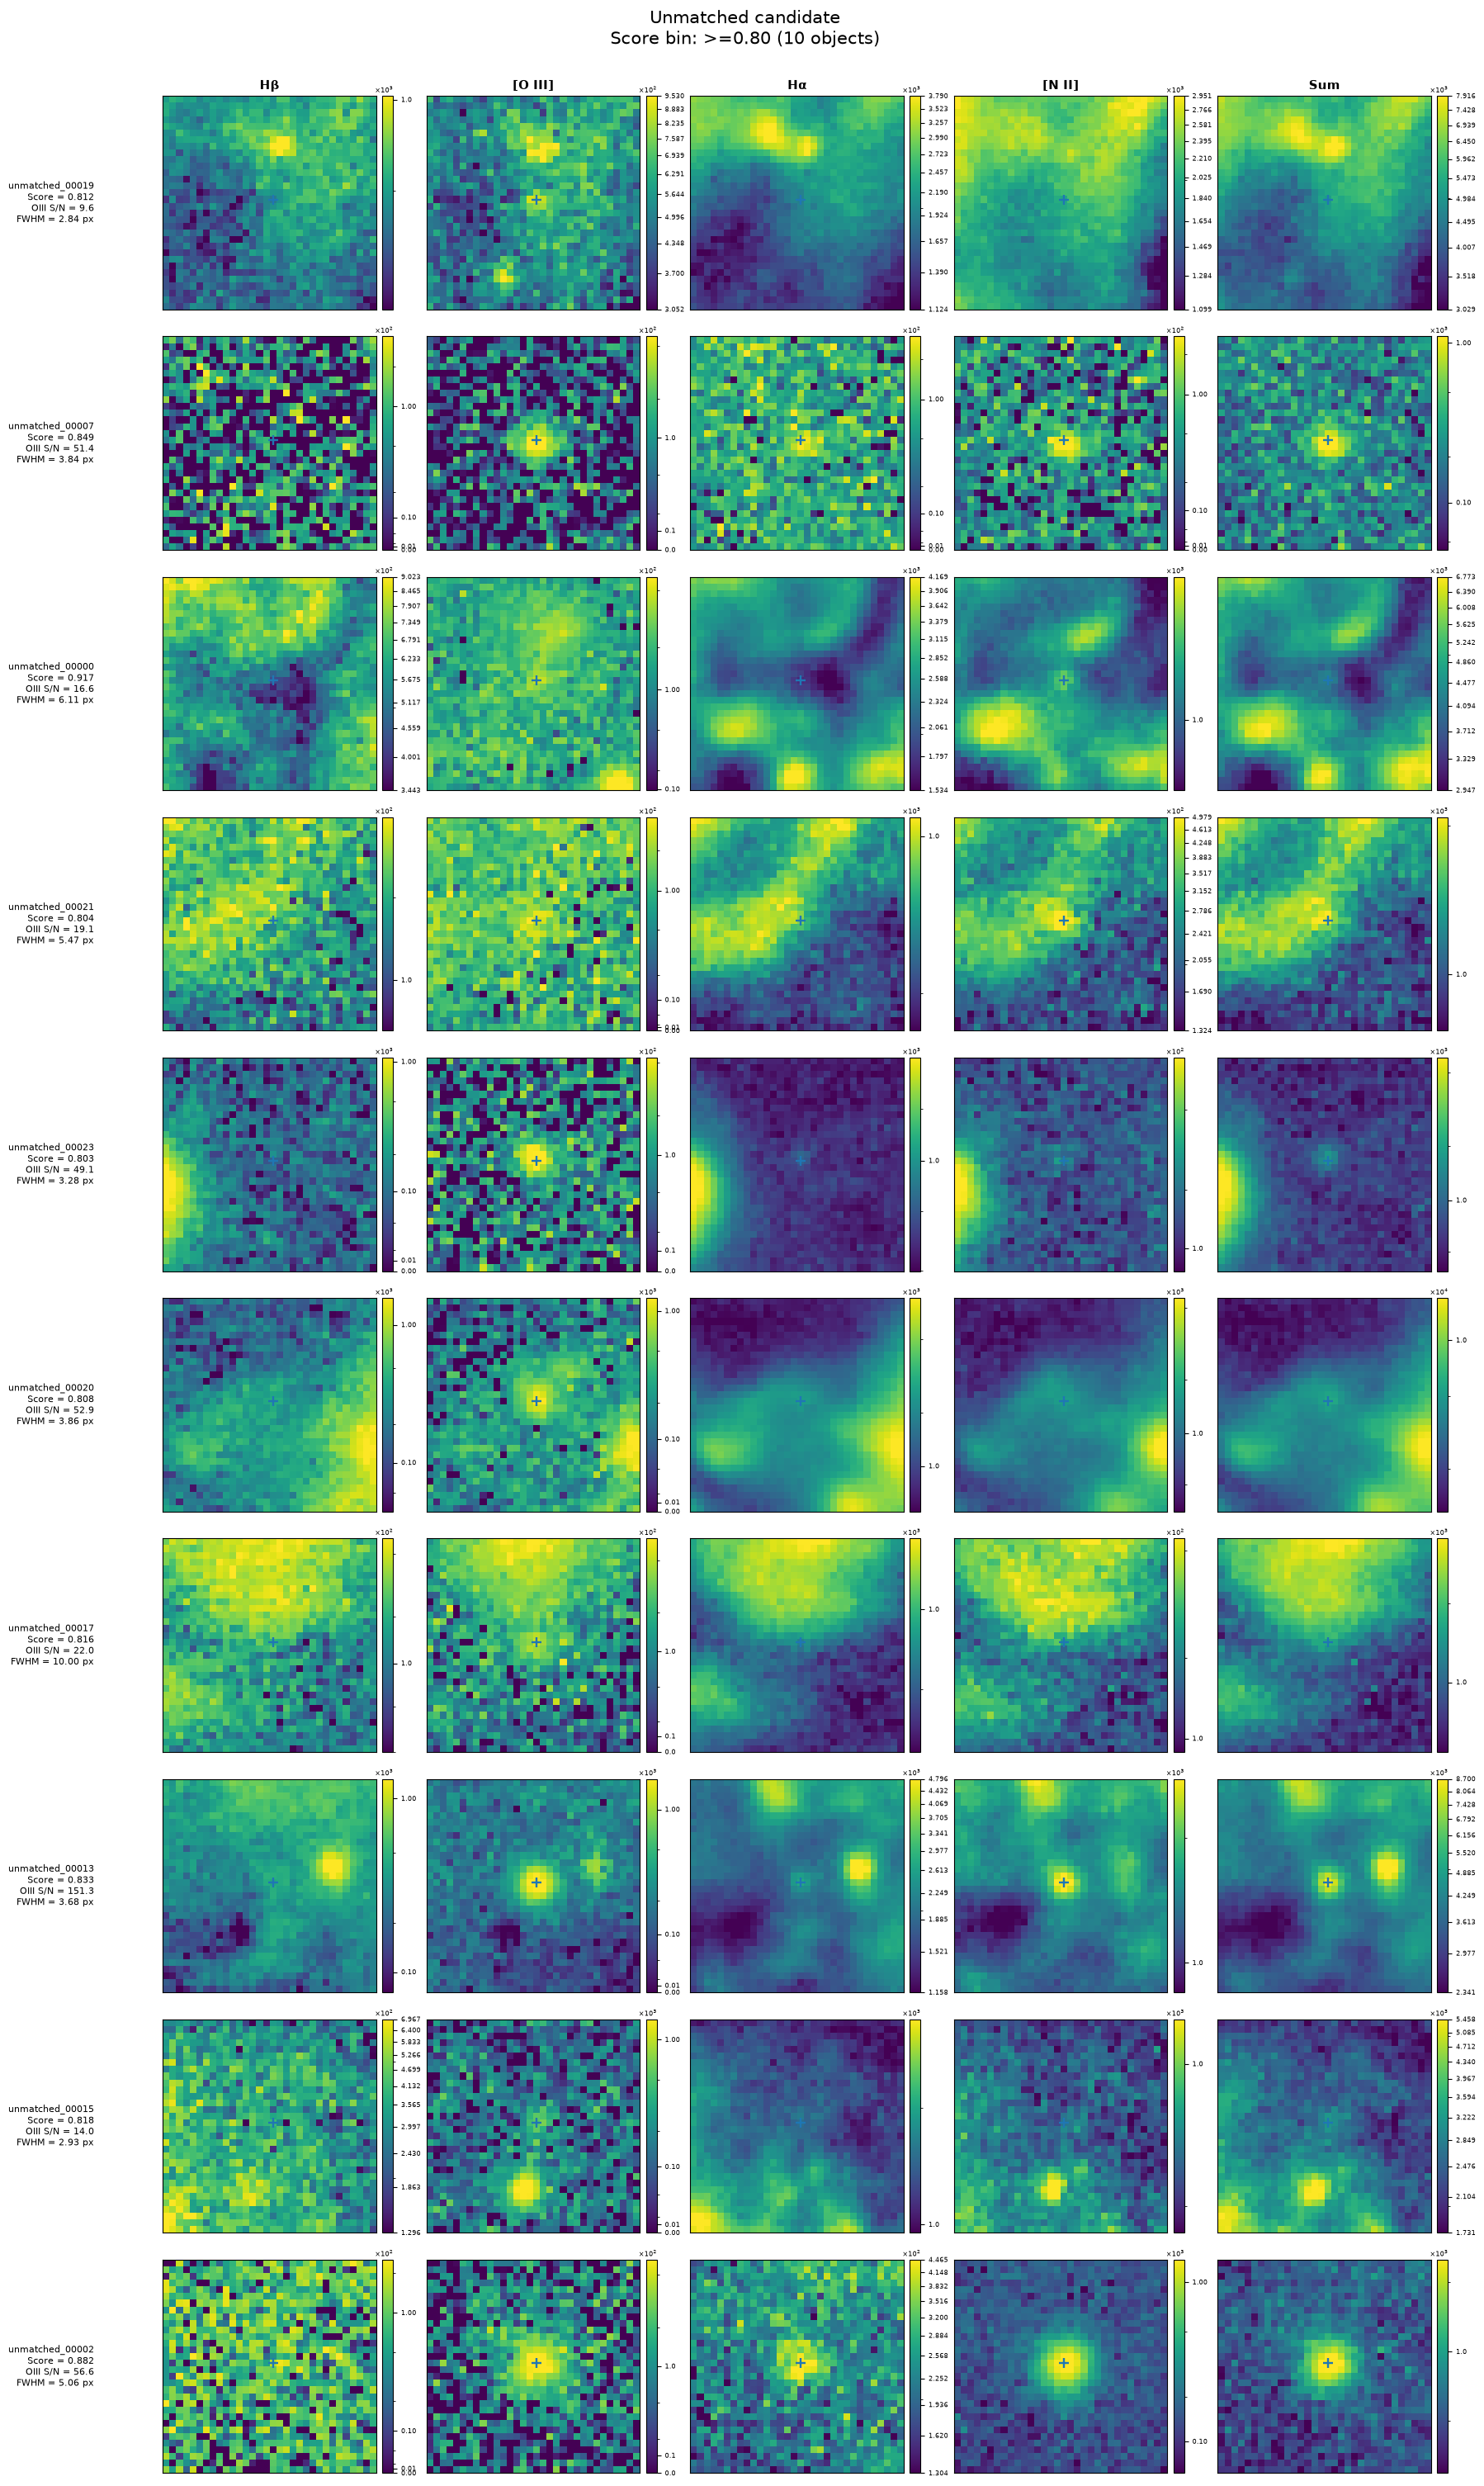

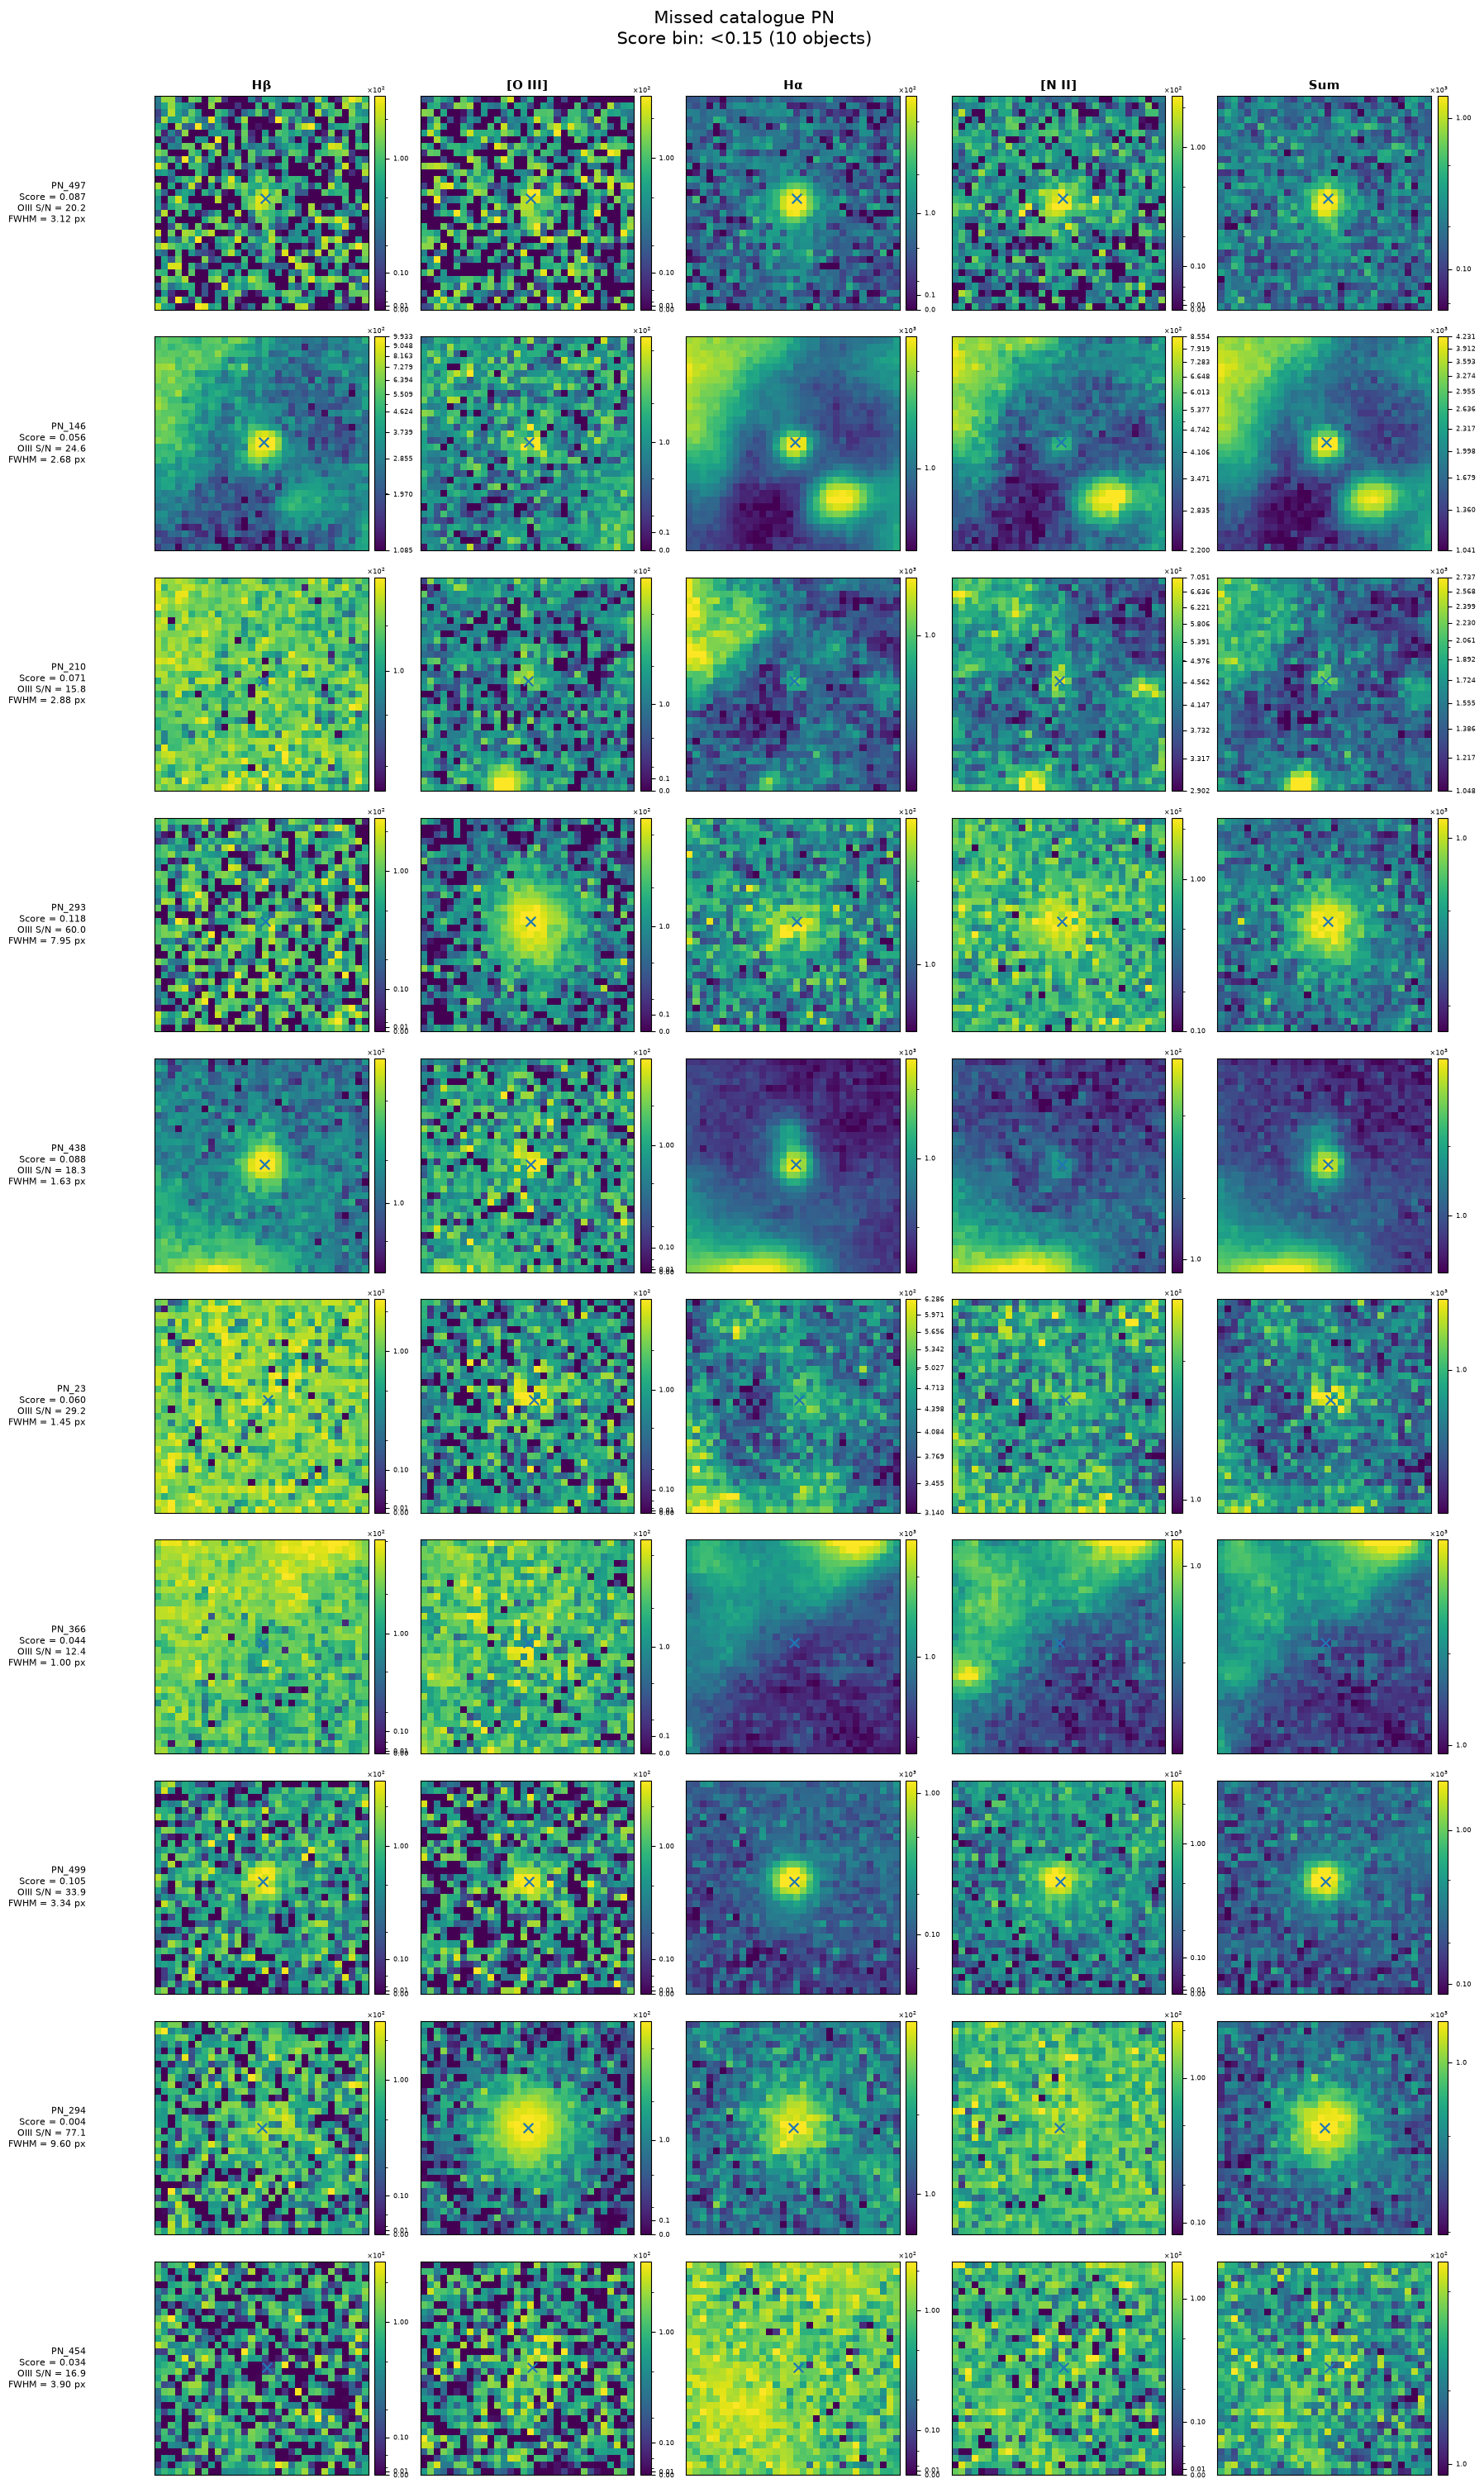

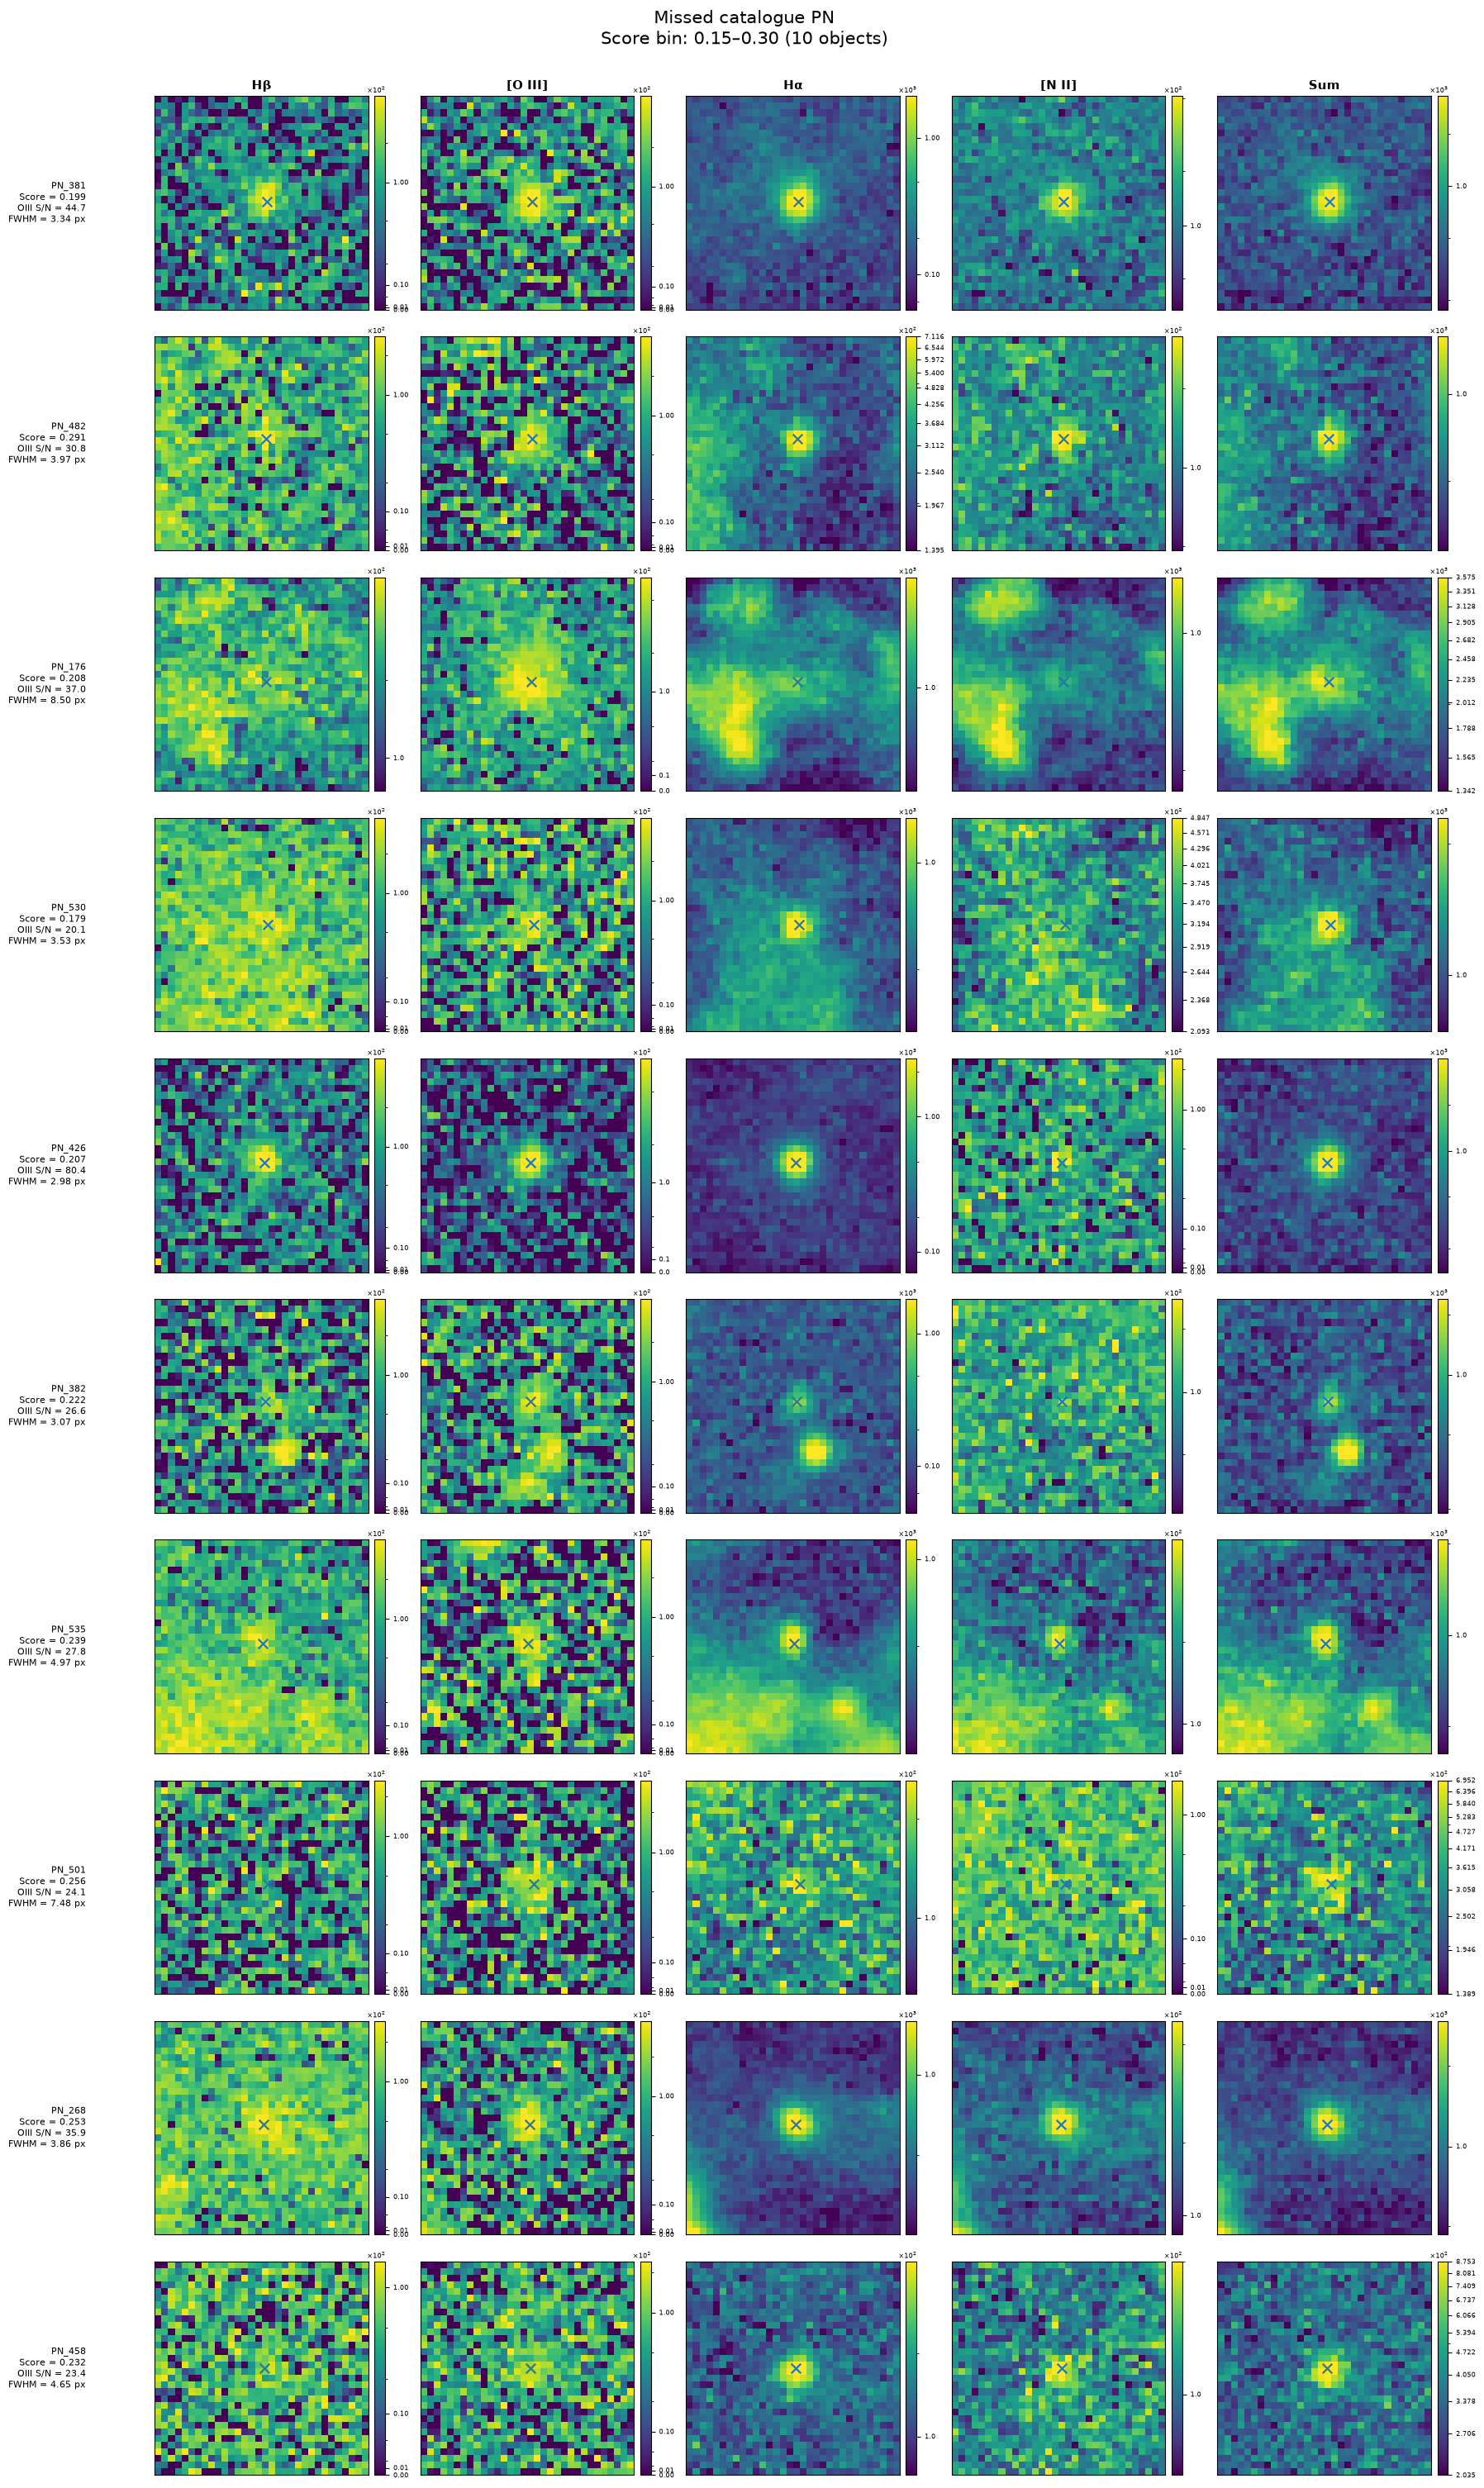

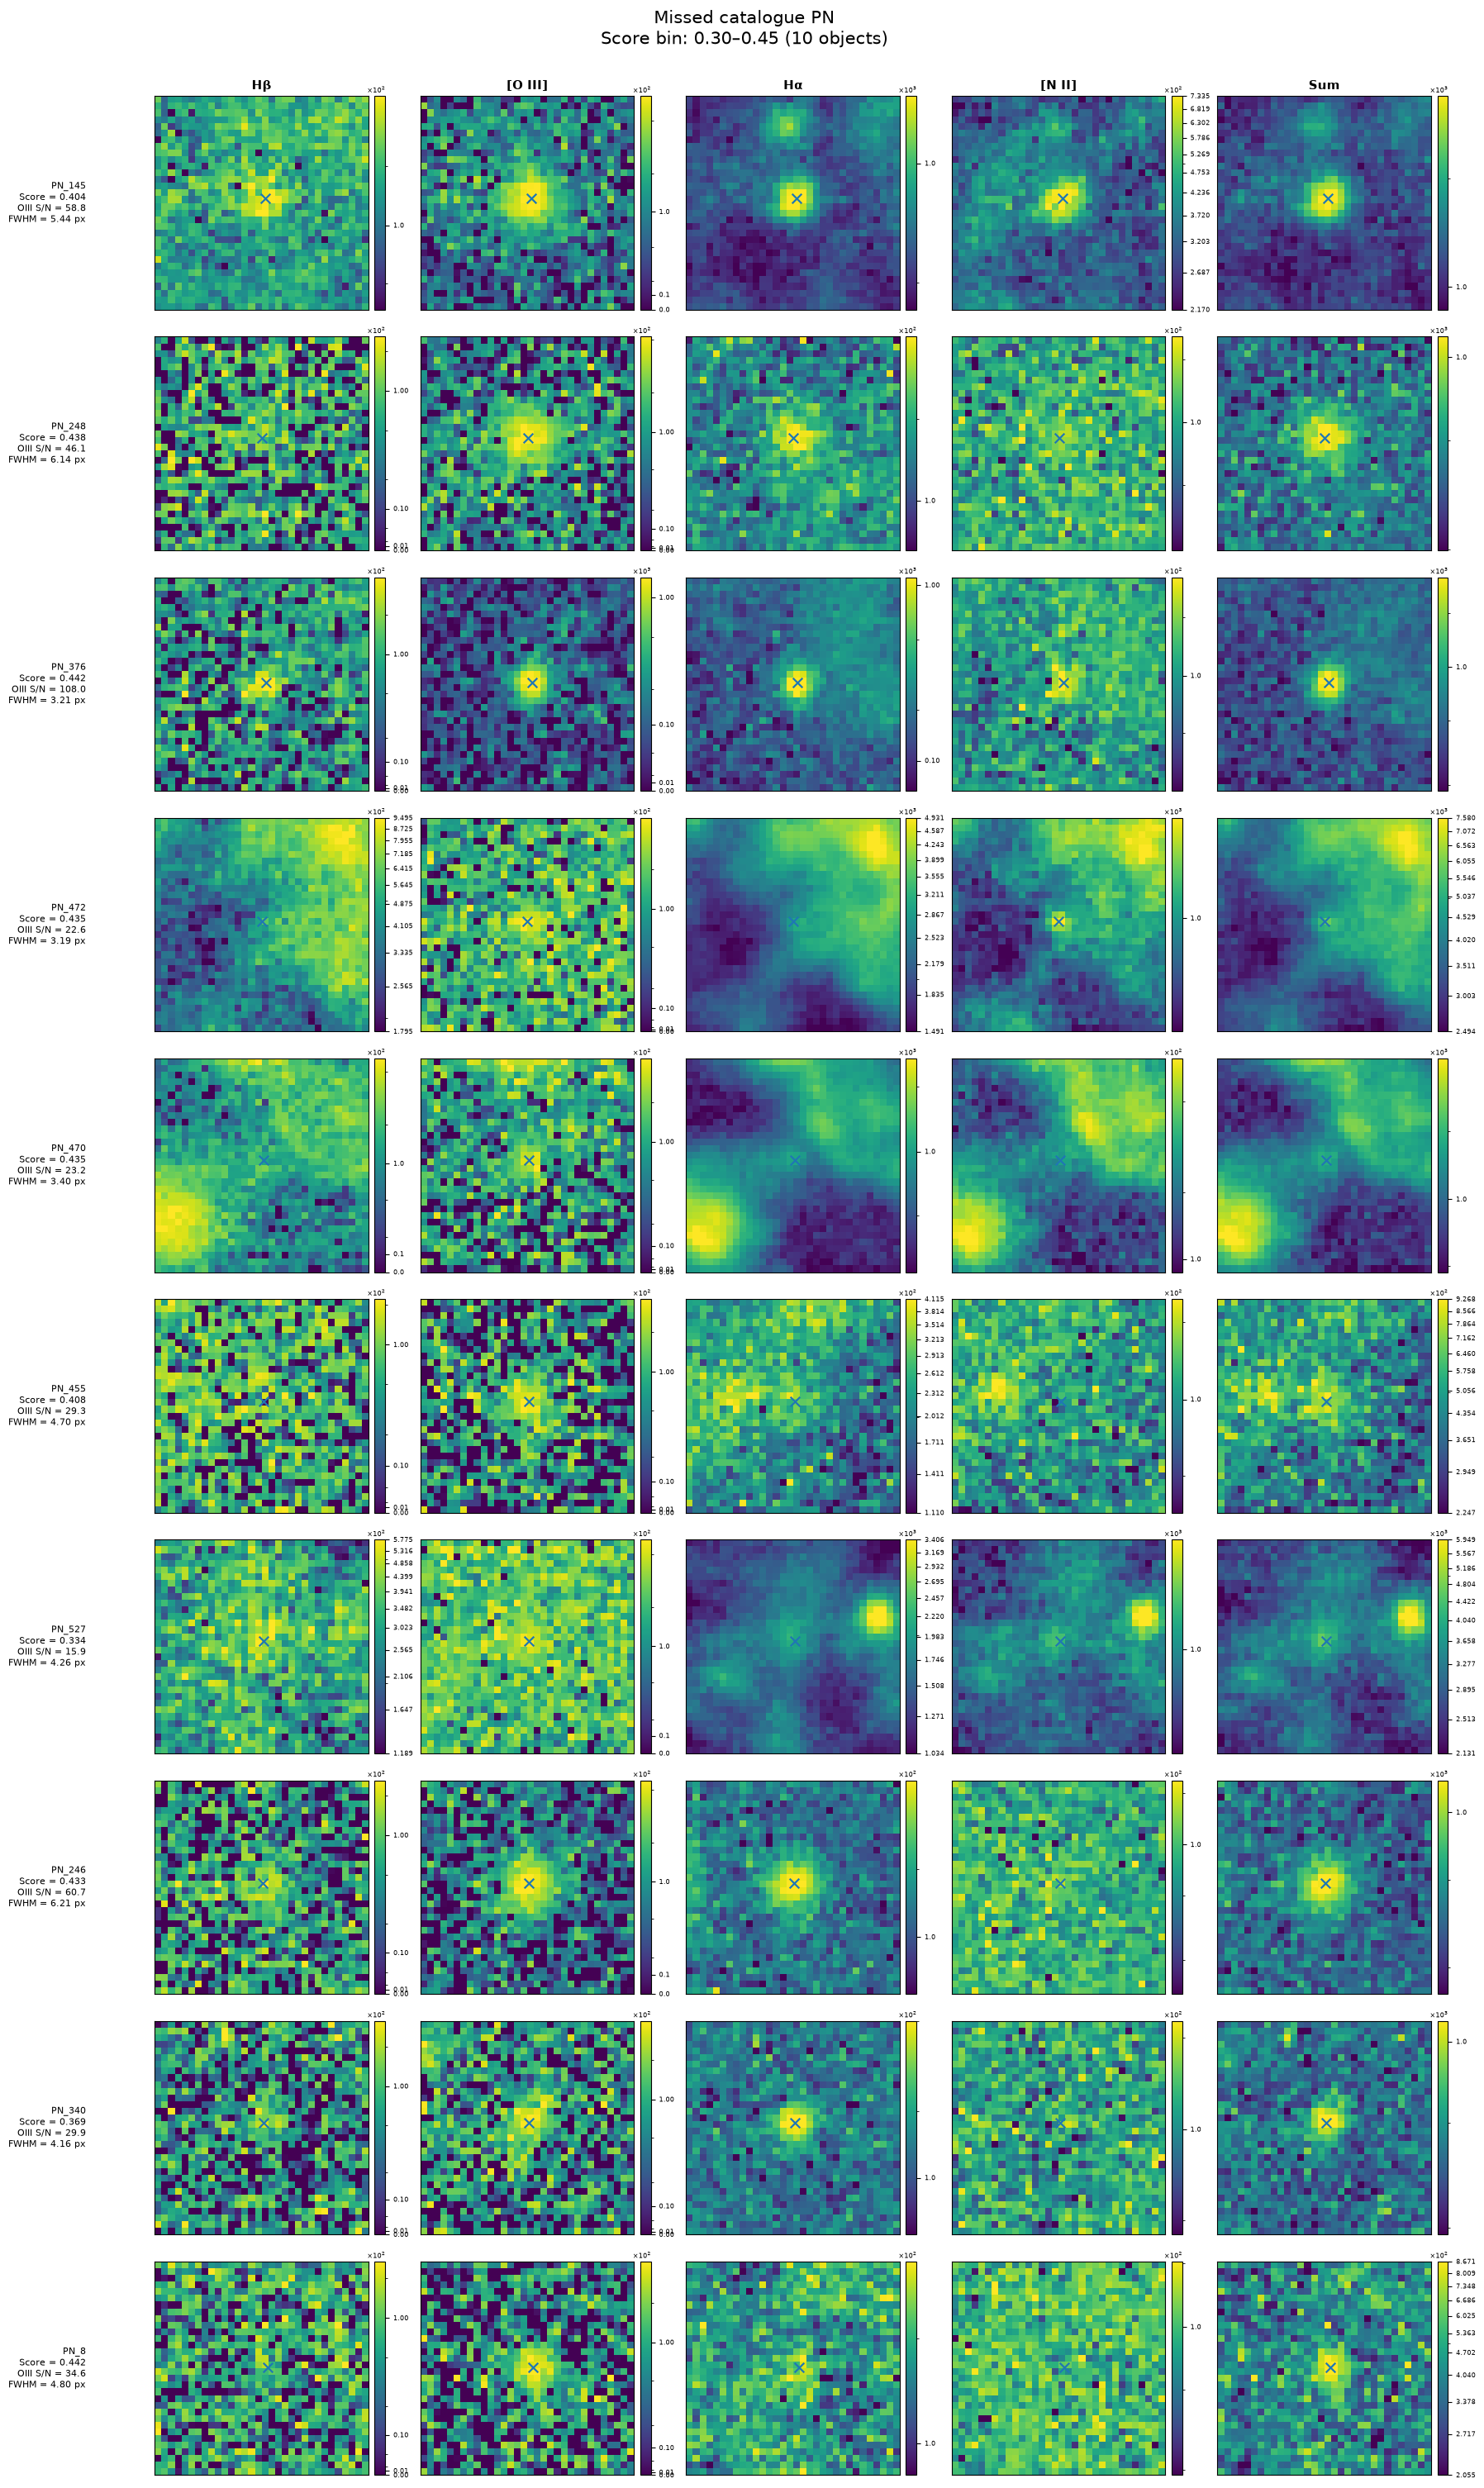

In [9]:
# ============================================================
# 30 EXAMPLES PER POPULATION:
#   10 objects from each of 3 score bins
#
# DISPLAY:
#   Hbeta | OIII | Halpha | NII | Sum of all 4 channels
#
# POPULATIONS:
#   - Recovered catalogue PN
#   - Missed catalogue PN
#   - Unmatched candidate
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from matplotlib.colors import AsinhNorm


# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

N_PER_BIN = 10
RANDOM_SEED = 20260916
CUTOUT_SIZE = 32

DISPLAY_LOW_PERCENTILE = 1.0
DISPLAY_HIGH_PERCENTILE = 99.5

POP_MATCHED = "Recovered catalogue PN"
POP_MISSED = "Missed catalogue PN"
POP_UNMATCHED = "Unmatched candidate"


# ------------------------------------------------------------
# Score bins
# ------------------------------------------------------------

# For populations that actually produced detections
DETECTED_SCORE_BINS = [
    (0.45, 0.60, "0.45–0.60"),
    (0.60, 0.80, "0.60–0.80"),
    (0.80, np.inf, ">=0.80"),
]

# Missed catalogue PNe are below the 0.45 detection threshold.
# network_score should be their maximum heatmap value near
# the catalogue position.
MISSED_SCORE_BINS = [
    (0.00, 0.15, "<0.15"),
    (0.15, 0.30, "0.15–0.30"),
    (0.30, 0.45, "0.30–0.45"),
]


# ------------------------------------------------------------
# Load all 4 flux maps
# ------------------------------------------------------------

with fits.open(ORIGINAL_FITS_PATH) as hdul:

    hb_flux = np.asarray(
        hdul["HB4861_FLUX"].data,
        dtype=np.float32,
    ).squeeze()

    oiii_flux = np.asarray(
        hdul["OIII5006_FLUX"].data,
        dtype=np.float32,
    ).squeeze()

    ha_flux = np.asarray(
        hdul["HA6562_FLUX"].data,
        dtype=np.float32,
    ).squeeze()

    nii_flux = np.asarray(
        hdul["NII6583_FLUX"].data,
        dtype=np.float32,
    ).squeeze()


# Sum in the original physical flux space
sum_flux = (
    hb_flux
    + oiii_flux
    + ha_flux
    + nii_flux
)


CHANNEL_IMAGES = {
    "Hβ": hb_flux,
    "[O III]": oiii_flux,
    "Hα": ha_flux,
    "[N II]": nii_flux,
    "Sum": sum_flux,
}


# ------------------------------------------------------------
# Helper: fixed 32x32 cutout
# ------------------------------------------------------------

def extract_cutout(image, x, y, size=32):

    half = size // 2

    xc = int(np.round(x))
    yc = int(np.round(y))

    x0 = xc - half
    y0 = yc - half

    x1 = x0 + size
    y1 = y0 + size

    h, w = image.shape

    if (
        x0 < 0
        or y0 < 0
        or x1 > w
        or y1 > h
    ):
        return None, None

    return image[y0:y1, x0:x1], (x0, y0)


# ------------------------------------------------------------
# Helper: display normalization
# ------------------------------------------------------------

def make_asinh_norm(cutout):

    finite = cutout[np.isfinite(cutout)]

    if finite.size == 0:
        return None

    vmin, vmax = np.percentile(
        finite,
        [
            DISPLAY_LOW_PERCENTILE,
            DISPLAY_HIGH_PERCENTILE,
        ],
    )

    if (
        not np.isfinite(vmin)
        or not np.isfinite(vmax)
        or vmax <= vmin
    ):
        vmin = np.nanmin(finite)
        vmax = np.nanmax(finite)

    if vmax <= vmin:
        vmax = vmin + 1.0

    linear_width = max(
        0.05 * (vmax - vmin),
        np.finfo(float).eps,
    )

    return AsinhNorm(
        linear_width=linear_width,
        vmin=vmin,
        vmax=vmax,
    )


# ------------------------------------------------------------
# Sample 10 objects from each score bin
# ------------------------------------------------------------

def sample_score_bins(
    table,
    population,
    score_bins,
    n_per_bin=10,
    seed=123,
):

    population_df = table[
        (table["population"] == population)
        & (~table["edge_object"].fillna(True))
        & np.isfinite(table["center_x"])
        & np.isfinite(table["center_y"])
        & np.isfinite(table["network_score"])
    ].copy()

    samples = []

    for bin_i, (low, high, label) in enumerate(score_bins):

        if np.isinf(high):

            in_bin = population_df[
                population_df["network_score"] >= low
            ].copy()

        else:

            in_bin = population_df[
                (population_df["network_score"] >= low)
                & (population_df["network_score"] < high)
            ].copy()

        n_available = len(in_bin)
        n_take = min(n_per_bin, n_available)

        if n_take == 0:

            print(
                f"WARNING: {population}, "
                f"score bin {label}: no objects."
            )

            continue

        if n_take < n_per_bin:

            print(
                f"WARNING: {population}, "
                f"score bin {label}: "
                f"only {n_available} objects available."
            )

        sampled = in_bin.sample(
            n=n_take,
            replace=False,
            random_state=seed + bin_i,
        ).copy()

        sampled["score_bin"] = label

        samples.append(sampled)

    if len(samples) == 0:
        return pd.DataFrame()

    return pd.concat(
        samples,
        ignore_index=True,
    )


sample_matched = sample_score_bins(
    diagnostic_table,
    POP_MATCHED,
    DETECTED_SCORE_BINS,
    n_per_bin=N_PER_BIN,
    seed=RANDOM_SEED,
)

sample_unmatched = sample_score_bins(
    diagnostic_table,
    POP_UNMATCHED,
    DETECTED_SCORE_BINS,
    n_per_bin=N_PER_BIN,
    seed=RANDOM_SEED + 100,
)

sample_missed = sample_score_bins(
    diagnostic_table,
    POP_MISSED,
    MISSED_SCORE_BINS,
    n_per_bin=N_PER_BIN,
    seed=RANDOM_SEED + 200,
)


visual_sample_90 = pd.concat(
    [
        sample_matched,
        sample_missed,
        sample_unmatched,
    ],
    ignore_index=True,
)


print("\nSample sizes:")
display(
    visual_sample_90
    .groupby(["population", "score_bin"])
    .size()
    .rename("N")
    .reset_index()
)


# Optional save
visual_sample_90.to_csv(
    OUTPUT_DIR / "visual_sample_30_each.csv",
    index=False,
)


# ============================================================
# PLOTTING
# ============================================================

from matplotlib.ticker import ScalarFormatter


def clean_value(value, fmt=".2f"):
    """Safely format finite values."""
    try:
        value = float(value)
        if np.isfinite(value):
            return format(value, fmt)
    except Exception:
        pass

    return "—"


def plot_score_bin(
    sample,
    population,
    score_bin,
):

    chosen = sample[
        (sample["population"] == population)
        & (sample["score_bin"] == score_bin)
    ].copy().reset_index(drop=True)

    if len(chosen) == 0:
        return

    n_objects = len(chosen)
    n_channels = len(CHANNEL_IMAGES)

    fig, axes = plt.subplots(
        n_objects,
        n_channels,
        figsize=(18, 3.0 * n_objects),
        squeeze=False,
    )

    # --------------------------------------------------------
    # Loop through objects
    # --------------------------------------------------------

    for row_i, (_, source) in enumerate(chosen.iterrows()):

        x_center = float(source["center_x"])
        y_center = float(source["center_y"])

        # ----------------------------------------------------
        # Quantities shown for EVERY object
        # ----------------------------------------------------

        score = source.get("network_score", np.nan)
        oiii_snr = source.get("oiii_snr", np.nan)
        fwhm = source.get("moffat_fwhm_pix", np.nan)

        score_text = clean_value(score, ".3f")
        snr_text = clean_value(oiii_snr, ".1f")
        fwhm_text = clean_value(fwhm, ".2f")

        object_info = (
            f"{source['object_id']}\n"
            f"Score = {score_text}\n"
            f"OIII S/N = {snr_text}\n"
            f"FWHM = {fwhm_text} px"
        )

        # Add localization error for matched catalogue PNe
        if (
            population == POP_MATCHED
            and "match_distance_pix" in source.index
            and np.isfinite(source["match_distance_pix"])
        ):
            object_info += (
                f"\nΔr = "
                f"{source['match_distance_pix']:.2f} px"
            )

        # ----------------------------------------------------
        # Five image panels
        # ----------------------------------------------------

        for col_i, (channel_name, image) in enumerate(
            CHANNEL_IMAGES.items()
        ):

            ax = axes[row_i, col_i]

            cutout, origin = extract_cutout(
                image,
                x_center,
                y_center,
                size=CUTOUT_SIZE,
            )

            if cutout is None:

                ax.text(
                    0.5,
                    0.5,
                    "No cutout",
                    ha="center",
                    va="center",
                )

                ax.axis("off")
                continue

            norm = make_asinh_norm(cutout)

            im = ax.imshow(
                cutout,
                origin="lower",
                norm=norm,
            )

            x0, y0 = origin

            # ------------------------------------------------
            # Position markers
            # ------------------------------------------------

            if population == POP_MATCHED:

                # Network position
                ax.scatter(
                    x_center - x0,
                    y_center - y0,
                    marker="+",
                    s=85,
                    linewidths=1.7,
                )

                # Catalogue position
                ax.scatter(
                    float(source["catalog_x"]) - x0,
                    float(source["catalog_y"]) - y0,
                    marker="x",
                    s=65,
                    linewidths=1.5,
                )

            elif population == POP_MISSED:

                # Catalogue position
                ax.scatter(
                    float(source["catalog_x"]) - x0,
                    float(source["catalog_y"]) - y0,
                    marker="x",
                    s=70,
                    linewidths=1.6,
                )

            elif population == POP_UNMATCHED:

                # Network position
                ax.scatter(
                    x_center - x0,
                    y_center - y0,
                    marker="+",
                    s=85,
                    linewidths=1.7,
                )

            # ------------------------------------------------
            # Column headings
            # ------------------------------------------------

            if row_i == 0:

                ax.set_title(
                    channel_name,
                    fontsize=11,
                    fontweight="bold",
                )

            ax.set_xticks([])
            ax.set_yticks([])

            # ------------------------------------------------
            # Object information on LEFT of first panel
            # ------------------------------------------------

            if col_i == 0:

                ax.set_ylabel(
                    object_info,
                    fontsize=8,
                    rotation=0,
                    ha="right",
                    va="center",
                    labelpad=60,
                )

            # ------------------------------------------------
            # CLEAN COLORBAR
            # ------------------------------------------------

            cbar = fig.colorbar(
                im,
                ax=ax,
                fraction=0.046,
                pad=0.025,
            )

            # Scientific notation instead of ugly long decimals
            formatter = ScalarFormatter(useMathText=True)
            formatter.set_scientific(True)
            # Force scientific notation for very small/large fluxes
            formatter.set_powerlimits((-2, 2))
            cbar.formatter = formatter
            cbar.update_ticks()
            cbar.ax.tick_params(labelsize=6)

            # Make the ×10^N offset smaller
            cbar.ax.yaxis.get_offset_text().set_fontsize(6)

    # --------------------------------------------------------
    # Figure title
    # --------------------------------------------------------

    fig.suptitle(
        f"{population}\n"
        f"Score bin: {score_bin} "
        f"({len(chosen)} objects)",
        fontsize=15,
        y=1.002,
    )

    plt.tight_layout()
    plt.savefig(f"{population}{score_bin}.png")
    plt.show()


# ============================================================
# MAKE ALL FIGURES
# ============================================================

# ------------------------------------------------------------
# MATCHED: 10 + 10 + 10
# ------------------------------------------------------------

for _, _, score_label in DETECTED_SCORE_BINS:

    plot_score_bin(
        sample_matched,
        POP_MATCHED,
        score_label,
    )


# ------------------------------------------------------------
# UNMATCHED: 10 + 10 + 10
# ------------------------------------------------------------

for _, _, score_label in DETECTED_SCORE_BINS:

    plot_score_bin(
        sample_unmatched,
        POP_UNMATCHED,
        score_label,
    )


# ------------------------------------------------------------
# MISSED: 10 + 10 + 10
# ------------------------------------------------------------

for _, _, score_label in MISSED_SCORE_BINS:

    plot_score_bin(
        sample_missed,
        POP_MISSED,
        score_label,
    )


## 6. Plot 20 objects from each population with colorbars

Each figure is a 4×5 grid of **raw [O III] 5007 flux** cutouts.

The display uses an asinh normalization only for visualization; the colorbar values remain in the original flux units.

Markers:
- matched: `+` network center, `x` catalogue coordinate;
- missed: `x` catalogue coordinate;
- unmatched: `+` network center.

Each panel gets its own colorbar because source brightness and local background can differ strongly.


## 7. Optional: localization error versus catalogue/source properties

These plots check whether localization worsens for faint, low-S/N, or broader catalogue PNe.


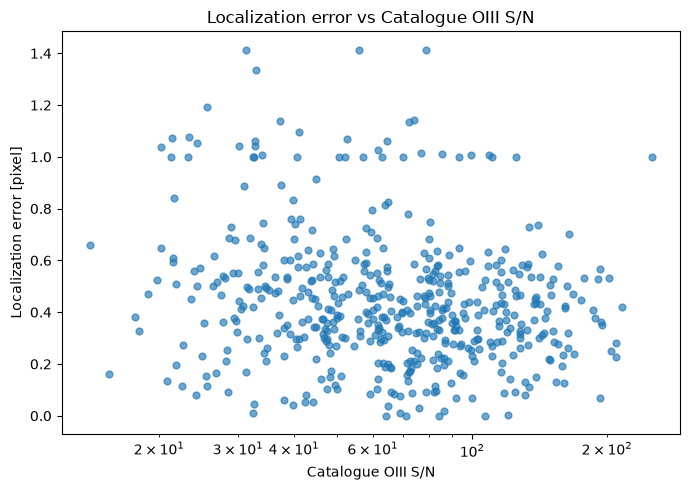

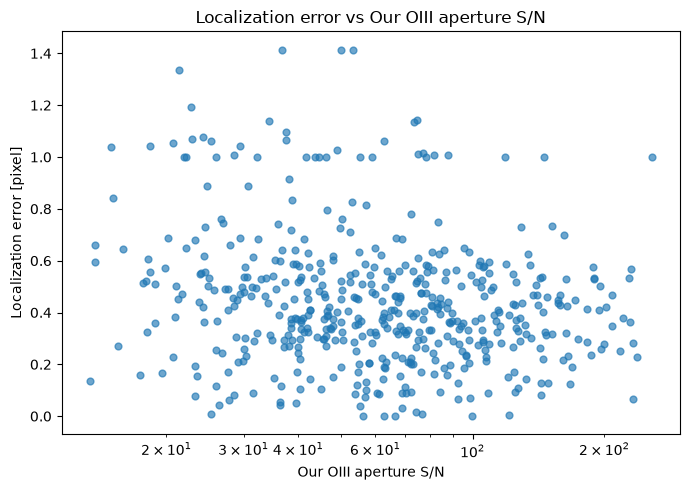

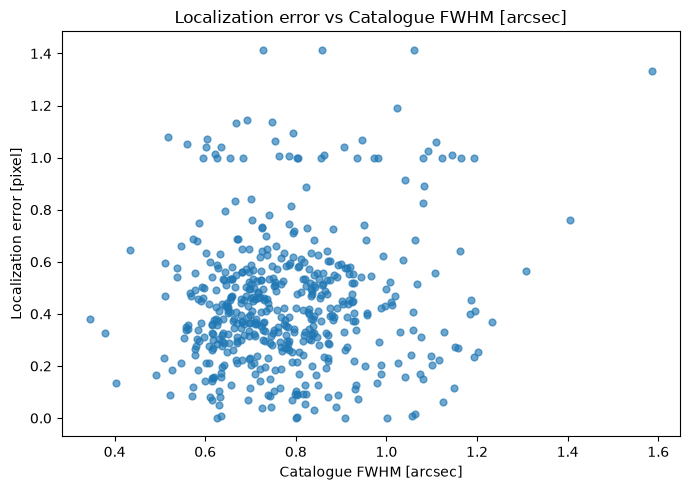

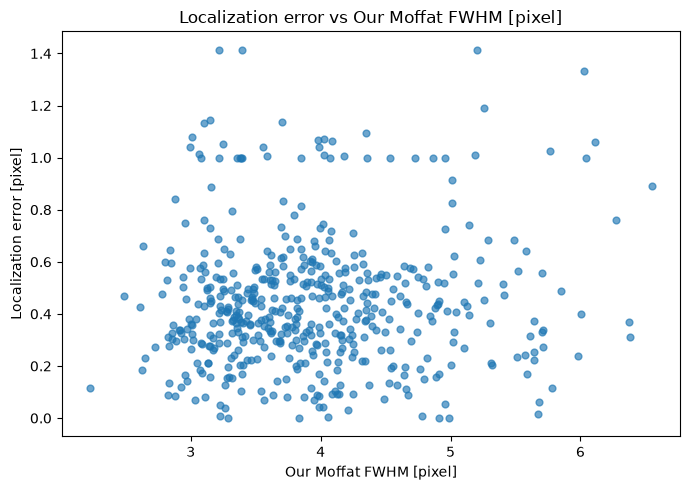

In [10]:
optional_x = [
    ("catalog_oiii_snr", "Catalogue OIII S/N", True),
    ("oiii_snr", "Our OIII aperture S/N", True),
    ("catalog_fwhm_arcsec", "Catalogue FWHM [arcsec]", False),
    ("moffat_fwhm_pix", "Our Moffat FWHM [pixel]", False),
]

for col, xlabel, logx in optional_x:
    if col not in matched.columns:
        continue

    good = (
        np.isfinite(matched[col])
        & np.isfinite(matched["localization_error_pix"])
    )
    if good.sum() == 0:
        continue

    x = matched.loc[good, col]
    y = matched.loc[good, "localization_error_pix"]

    plt.figure(figsize=(7, 5))
    plt.scatter(x, y, s=24, alpha=0.65)

    if logx and np.all(x > 0):
        plt.xscale("log")

    plt.xlabel(xlabel)
    plt.ylabel("Localization error [pixel]")
    plt.title(f"Localization error vs {xlabel}")
    plt.tight_layout()
    plt.show()


## Interpretation notes

- The **radial localization error** is defined only for matched catalogue PNe.
- A non-zero mean \(\Delta x\) or \(\Delta y\) suggests a systematic astrometric offset.
- The 68th, 90th, and 95th percentiles are more informative than the maximum for describing typical localization performance.
- The matched cutout grid lets you visually verify whether a large localization error is caused by an actual model offset, blending, or catalogue/astrometric uncertainty.
- Missed and unmatched samples are shown for qualitative comparison only; they do not have a catalogue-defined localization error.
